# LendingClub Credit-Risk Paper Reproduction — Structured Notebook

**Paper:** Gramifar, Kabir & Khan (2026), *Advanced Engineering Informatics* 74, 104638.

This notebook is organised as separate, labelled cells so each stage can be run, checked, and resumed independently: data audit, cleaning, feature engineering, macroeconomic joining, RUS, SMOTENC, ML tables, K-means discretisation, Tabu Search / comparison learners, EM parameter learning, inference, sensitivity, and every result figure/table implemented in the source workflow.

## Important reproduction notes
- Target coding follows the paper: `loan_status = 0` means **Charged-Off/default** and `1` means **Fully Paid**.
- Train/test split is temporal: 2007–2017 training and 2018 test. Resampling is applied only to training data.
- Primary BN structure learner is **Tabu Search**. Bayesian search, PC and Naive Bayes are comparison methods for Table A.8; Hill Climbing is not substituted for Tabu Search.
- BN parameters are estimated with the notebook's EM implementation. Earlier V5 files using MLE and V6 Hill-Climbing files are listed in the inventory for traceability, but are not silently treated as this run's results.
- Exact numerical equality with the paper is not guaranteed where the paper does not report every random seed, implementation detail, or search hyperparameter. The notebook prints a side-by-side comparison with reported paper values instead of overwriting discrepancies.
- The paper's Tables A.1–A.2 and Figures 1–3 are literature-review/framework material rather than outputs of the predictive pipeline. They are documented in the final inventory; this notebook focuses on reproducible analytical outputs (Tables 1–6, A.3–A.8; Figures 4–23 and A.1–A.2).

**Run guidance:** Execute from top to bottom once. Afterward, individual later cells can be rerun: resampling data, split data, per-model ML metrics, and fitted BN bundles are checkpointed in the new output folder.

## 0. Install dependencies (run once per fresh Colab runtime)

The data file is large, so use Google Colab with Drive storage. If packages are already installed, this cell may be skipped.

In [1]:
%pip install -q catboost lightgbm xgboost imbalanced-learn networkx pgmpy scikit-learn pandas numpy matplotlib scipy seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 10.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 43.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.6/162.6 kB 7.6 MB/s eta 0:00:00


## 1. Mount Google Drive and check previously saved files

This cell **does not delete or overwrite** the old output folders. It checks for the previously referenced files and prints which ones are actually present in your Drive.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os
ROOT = "/content/drive/MyDrive/LendingClub_Reproduction"
LEGACY_LOCATIONS = {
    "previous ML outputs": os.path.join(ROOT, "outputs"),
    "v3 paper-faithful outputs": os.path.join(ROOT, "outputs_paper_faithful_v3"),
    "v4 macro outputs": os.path.join(ROOT, "outputs_paper_faithful_v4"),
    "v5 BN outputs (includes earlier MLE experiment)": os.path.join(ROOT, "outputs_paper_faithful_v5"),
    "v6 Hill-Climb experiment (not primary paper method)": os.path.join(ROOT, "outputs_paper_faithful_v6"),
}
EXPECTED_LEGACY_FILES = {
    "previous ML outputs": ["train_df.pkl", "test_df.pkl", "rus_train.pkl", "smotenc_train.pkl", "CatBoost_feature_importance.csv", "Table_2_RUS.csv", "Table_3_SMOTENC.csv"],
    "v3 paper-faithful outputs": ["cache/rus_base.pkl", "cache/smote_base.pkl", "cache/smote_enr.pkl", "tables/Table2_ML_undersampling.csv", "tables/Table3_ML_SMOTENC.csv"],
    "v4 macro outputs": ["macro_data/macro_bn_train_discretized.pkl", "macro_data/macro_bn_test_discretized.pkl"],
    "v5 BN outputs (includes earlier MLE experiment)": ["macro_structure_learning/Macro_BN_Tabu_structure.pkl", "macro_parameter_learning/Macro_BN_fitted_model.pkl", "macro_prediction_evaluation/Macro_BN_v5_test_metrics.csv"],
    "v6 Hill-Climb experiment (not primary paper method)": ["structure_learning/V6_BN_structure.pkl", "structure_learning/V6_BN_edges.csv"],
}
print("ROOT:", ROOT)
for label, folder in LEGACY_LOCATIONS.items():
    print(f"\n[{label}] {folder}")
    found = False
    for rel in EXPECTED_LEGACY_FILES.get(label, []):
        p = os.path.join(folder, rel)
        if os.path.exists(p):
            print("  FOUND ", p)
            found = True
        else:
            print("  not found (will not assume it exists):", p)
    if not found:
        print("  No listed legacy files found in this folder.")

# New run is versioned separately to preserve old outputs.
CSV_PATH = "/content/drive/MyDrive/accepted_2007_to_2018Q4.csv"
OUT_DIR = os.path.join(ROOT, "outputs_paper_faithful_v7_structured")
print("\nDataset path:", CSV_PATH)
print("New outputs path:", OUT_DIR)
if not os.path.exists(CSV_PATH):
    print("ACTION REQUIRED: upload/copy accepted_2007_to_2018Q4.csv into the ROOT folder, or set CSV_PATH to its Drive path before running the raw-data cell.")

Mounted at /content/drive
ROOT: /content/drive/MyDrive/LendingClub_Reproduction

[previous ML outputs] /content/drive/MyDrive/LendingClub_Reproduction/outputs
  FOUND  /content/drive/MyDrive/LendingClub_Reproduction/outputs/train_df.pkl
  FOUND  /content/drive/MyDrive/LendingClub_Reproduction/outputs/test_df.pkl
  FOUND  /content/drive/MyDrive/LendingClub_Reproduction/outputs/rus_train.pkl
  FOUND  /content/drive/MyDrive/LendingClub_Reproduction/outputs/smotenc_train.pkl
  FOUND  /content/drive/MyDrive/LendingClub_Reproduction/outputs/CatBoost_feature_importance.csv
  FOUND  /content/drive/MyDrive/LendingClub_Reproduction/outputs/Table_2_RUS.csv
  FOUND  /content/drive/MyDrive/LendingClub_Reproduction/outputs/Table_3_SMOTENC.csv

[v3 paper-faithful outputs] /content/drive/MyDrive/LendingClub_Reproduction/outputs_paper_faithful_v3
  not found (will not assume it exists): /content/drive/MyDrive/LendingClub_Reproduction/outputs_paper_faithful_v3/cache/rus_base.pkl
  not found (will not as

## 2. Configuration, feature lists, and paper-reported comparison values

The constants in this cell preserve the paper's 29 candidate columns, reported 22-feature set, BN node sets, K-means bin counts, metrics, and reported values for Tables 2–6 and A.8. Search settings not explicitly fixed by the paper are marked as implementation settings in the code.

In [3]:
import os, gc, time, json, pickle, warnings, math, itertools
from collections import deque
import numpy as np
import pandas as pd
import matplotlib
if not os.environ.get("DISPLAY") and os.environ.get("MPLBACKEND") is None and "ipykernel" not in __import__("sys").modules:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
from scipy.special import gammaln
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.cluster import KMeans
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score, recall_score,
                             f1_score, brier_score_loss, roc_curve, confusion_matrix)
warnings.filterwarnings("ignore")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 50); pd.set_option("display.max_colwidth", None)

def _env(name, default, cast=str):
    v = os.environ.get(name)
    return default if v is None else cast(v)

# ---------------------------- USER SETTINGS ----------------------------
CSV_PATH       = _env("CSV_PATH", CSV_PATH)   # path set in Drive-check cell above
OUT_DIR        = _env("OUT_DIR", OUT_DIR)
RANDOM_STATE   = 42
CHUNKSIZE      = _env("CHUNKSIZE", 100_000, int)

TRAIN_YEARS    = list(range(2007, 2018))      # Section 4.2.4 / 4.2.5: 2007-2017 training
TEST_YEAR      = 2018                          # 2018 hold-out, never resampled
FEATURE_SELECTION = _env("FEATURE_SELECTION", "paper")   # "paper" -> the 22 features of Fig. 7 ; "catboost" -> CatBoost top-22
N_FINAL_FEATURES  = 22

# Bayesian network settings
BN_MAX_INDEGREE   = _env("BN_MAX_INDEGREE", 4, int)
STRUCT_ROWS       = _env("STRUCT_ROWS", 200_000, int)   # rows used to SCORE structures (parameters use all rows)
KMEANS_FIT_ROWS   = _env("KMEANS_FIT_ROWS", 300_000, int)
BDEU_ESS          = 10.0                                  # equivalent sample size for CPT smoothing
LW_SAMPLES        = _env("LW_SAMPLES", 150_000, int)      # samples per forward/backward inference query
PRIOR_SAMPLES     = _env("PRIOR_SAMPLES", 500_000, int)
TABU_PATIENCE     = _env("TABU_PATIENCE", 12, int)
TABU_MAX_ITER     = _env("TABU_MAX_ITER", 150, int)
PC_ROWS           = _env("PC_ROWS", 30_000, int)

# Optional switches for very long steps
RUN_ML            = _env("RUN_ML", "1") == "1"
KNN_TRAIN_CAP     = _env("KNN_TRAIN_CAP", 0, int)         # 0 = use all training rows for KNN (slow on 2M rows)
ML_MODELS_ONLY    = _env("ML_MODELS_ONLY", "")            # e.g. "Logistic Regression,XGBoost" for a quick run
CATBOOST_ITER     = 200

for sub in ("figures", "tables", "cache"):
    os.makedirs(os.path.join(OUT_DIR, sub), exist_ok=True)
FIG_DIR, TAB_DIR, CACHE_DIR = [os.path.join(OUT_DIR, s) for s in ("figures", "tables", "cache")]

def show_save(fig, name, dpi=150):
    fig.savefig(os.path.join(FIG_DIR, name + ".png"), dpi=dpi, bbox_inches="tight")
    plt.show(); plt.close(fig)

def save_table(df, name, index=True):
    df.to_csv(os.path.join(TAB_DIR, name + ".csv"), index=index)

# ---------------------------- constants from the paper ----------------------------
# Table A.3 (29 first-selected variables, incl. loan_status and issue_d)
SELECTED_COLS = ["loan_amnt","term","int_rate","installment","grade","sub_grade","emp_title","emp_length",
                 "home_ownership","annual_inc","verification_status","issue_d","loan_status","purpose","title",
                 "zip_code","addr_state","dti","earliest_cr_line","open_acc","pub_rec","revol_bal","recoveries",
                 "revol_util","total_acc","initial_list_status","application_type","mort_acc","pub_rec_bankruptcies"]
# Fig. 7 : the 22 features kept after CatBoost importance ranking
PAPER_22 = ["int_rate","recoveries","annual_inc","term","loan_amnt","sub_grade","revol_bal","dti","revol_util",
            "mort_acc","purpose","installment","home_ownership","addr_state","open_acc","earliest_cr_line",
            "verification_status","total_acc","application_type","pub_rec","pub_rec_bankruptcies","initial_list_status"]
MACRO3 = ["inflation_rate_squared","inflation_rate_times_GDP_growth","unemployment_rate"]
CAT_FEATS = ["sub_grade","purpose","home_ownership","verification_status","addr_state","initial_list_status","application_type"]
CAT_SMOTE = CAT_FEATS + ["term"]            # term is nominal for SMOTENC (36/60) but numeric for the ML models

# Domain-expert outlier thresholds (taken from the value ranges reported in Table A.7)
OUTLIER_RULES = {"annual_inc":(750,250000),"dti":(0,50),"open_acc":(1,40),"pub_rec":(0,40),"mort_acc":(0,29),
                 "revol_bal":(0,249280),"revol_util":(0,119.3),"total_acc":(2,80),"loan_amnt":(500,40000),
                 "installment":(16.08,1714.54),"int_rate":(5.31,30.99),"recoveries":(0,39444.37)}

# Table A.7: number of K-means intervals per continuous BN variable
K_BINS = {"annual_inc":6,"dti":10,"earliest_cr_line":5,"inflation_rate_squared":10,"inflation_rate_times_GDP_growth":10,
          "installment":5,"int_rate":10,"loan_amnt":5,"mort_acc":3,"open_acc":5,"pub_rec":3,"recoveries":10,
          "revol_bal":5,"revol_util":5,"total_acc":5,"unemployment_rate":10}
# BN node sets (Fig. 8 and Fig. 9)
BN_BASE_NODES  = ["loan_status","term","revol_bal","total_acc","home_ownership","earliest_cr_line","recoveries",
                  "sub_grade","loan_amnt","application_type","revol_util","dti","int_rate","mort_acc","annual_inc",
                  "open_acc","installment","pub_rec_bankruptcies"]
BN_ENRICH_NODES = BN_BASE_NODES + ["pub_rec"] + MACRO3

MODEL_ORDER = ["Gradient Boosting","LightGBM","XGBoost","Random Forest","Logistic Regression","Neural Network",
               "Decision Tree","K Nearest Neighbors","Gaussian Naive Bayes"]
METRICS = ["Accuracy","ROC-AUC","Precision","Recall","F1-Score","KS_Statistic","Brier Score","ECE"]

save_table(pd.DataFrame({"Selected variable": SELECTED_COLS}), "TableA3_selected_variables", index=False)

# ---------------------------- numbers REPORTED in the paper (for side-by-side comparison) ----------------------------
def _tbl(rows): return pd.DataFrame(rows, index=MODEL_ORDER, columns=METRICS)
PAPER_T2 = _tbl([[.868,.737,.881,.974,.925,.340,.119,.123],[.877,.736,.879,.991,.931,.335,.116,.119],
  [.869,.739,.881,.977,.926,.341,.119,.124],[.879,.738,.878,.995,.933,.344,.118,.129],[.870,.715,.879,.980,.927,.304,.121,.120],
  [.857,.758,.887,.951,.918,.363,.119,.123],[.869,.720,.879,.979,.926,.319,.120,.116],[.801,.679,.883,.881,.882,.261,.150,.177],
  [.882,.719,.877,1.000,.934,.322,.118,.118]])
PAPER_T3 = _tbl([[.867,.750,.883,.972,.925,.350,.112,.090],[.868,.749,.883,.972,.925,.347,.110,.070],
  [.871,.750,.882,.977,.927,.349,.109,.068],[.871,.754,.882,.978,.928,.357,.118,.127],[.847,.745,.886,.939,.912,.344,.126,.129],
  [.861,.751,.881,.964,.921,.353,.113,.057],[.861,.739,.884,.961,.921,.334,.113,.074],[.683,.676,.892,.709,.790,.257,.193,.216],
  [.825,.750,.892,.902,.897,.363,.166,.164]])
PAPER_T4 = _tbl([[.875,.769,.885,.979,.930,.378,.103,.059],[.869,.768,.889,.965,.926,.377,.109,.089],
  [.864,.770,.890,.958,.923,.380,.111,.095],[.880,.765,.881,.991,.933,.369,.109,.100],[.855,.755,.889,.947,.917,.364,.120,.116],
  [.851,.759,.877,.953,.920,.368,.121,.114],[.861,.739,.884,.961,.921,.334,.113,.074],[.683,.676,.892,.709,.790,.257,.193,.216],
  [.825,.750,.892,.902,.897,.363,.166,.164]])
PAPER_BN_ROW = pd.DataFrame([[.866,.757,.885,.935,.908,.364,.109,.088]], index=["Bayesian Network"], columns=METRICS)
PAPER_T5 = pd.DataFrame({"Accuracy":[.846,.866],"ROC-AUC":[.725,.757]}, index=["Baseline BN","Macro-Enriched BN"])
PAPER_A8 = pd.DataFrame({"AUC":[.725,.698,.690,.681],"KS":[.360,.343,.331,.323],"Brier score":[.111,.113,.116,.131]},
                        index=["Tabu search","Bayesian search","PC","Naive Bayes"])

def compare_with_paper(ours, paper, title):
    """Print our table, the paper's table and the difference (ours - paper)."""
    common_r = [r for r in paper.index if r in ours.index]; common_c = [c for c in paper.columns if c in ours.columns]
    o = ours.loc[common_r, common_c].astype(float); p = paper.loc[common_r, common_c].astype(float)
    print(f"\n===== {title}: REPRODUCED =====");  print(o.round(3).to_string())
    print(f"----- {title}: PAPER -----");         print(p.round(3).to_string())
    print(f"----- {title}: DIFFERENCE (reproduced - paper) -----"); print((o - p).round(3).to_string())

## 3. Macroeconomic reference tables (Tables A.4–A.6) and feature engineering

The paper aligns macroeconomic values to each loan using state and issue year. It then creates three engineered predictors: squared inflation, inflation × GDP growth, and unemployment rate. The source tables are transcribed from the paper; they are not fetched live.

In [4]:
# ---------------------------- Macro-economic tables A.4 - A.6 (transcribed from the paper) ----------------------------
INFLATION = {2008:3.84,2009:-0.36,2010:1.64,2011:3.16,2012:2.07,2013:1.46,2014:1.62,2015:0.12,2016:1.26,2017:2.13,2018:2.44}
A5_GDP = """AL 2.8 -2.2 3.5 3.1 1.9 0.4 2.8 4 1.3 3.3 3.4
AK 9.3 -1.2 4.9 5.8 1.8 -2 5.4 2.9 -2.1 1.7 4.4
AZ 0 -6 0.9 4.4 3.1 1.5 3.6 4.2 3.2 5.1 4.7
AR 3.6 -2.3 2.6 6.1 6.2 0 5.3 2.7 2.3 3 3.9
CA 0.7 -4 3.5 5.5 5 0.6 5.3 6.3 3.8 4.2 4.8
CO 2.9 -6.3 1.4 7.1 4 3.5 6.7 2.3 -0.2 5.6 6.7
CT 6 -1.6 3 2.6 0.9 -2.4 4 2.7 2 2.4 4.4
DE -0.7 -0.5 0.1 6.5 0 0.4 3.2 4.1 2 3.8 5.3
DC 2.1 -1 5.3 6 0.8 -0.7 5.1 6 3.6 2.7 3.4
FL 0 -6.1 5.4 4.3 1.9 -1.1 5.2 4.9 1.7 5.9 5.3
GA -0.5 -3 1.5 5.8 1.3 0.6 5.5 5 2.9 4.9 4
HI 3.9 -1.8 0.9 3.1 1.8 0.1 4.4 3.7 3 4 2.1
ID 0.7 -4.6 2.4 4.7 4.1 2.6 4 4.6 2.2 3.9 5
IL 2.6 -5 2.5 4.7 4.2 1.7 3.9 4.4 1.3 3.3 5.7
IN 4.2 -3 4.1 5.9 3.9 0.7 3.3 3.5 2.4 3.3 4.5
IA 5.8 -3.2 2.5 7 4.1 1.1 2.6 3 0.5 2.4 4.3
KS 8.8 -4.1 1.1 7.7 4.7 1.7 1.4 0.7 0.3 3.3 4.2
KY 4.1 -1.9 3.1 4.3 3 0.4 4.1 4.1 1.4 2.8 3.1
LA 5.9 -4 3.4 2.4 4.4 0.8 3.7 -0.1 -0.8 3.2 4.5
ME 4.4 0.4 2.5 3.9 1.2 -0.1 3 4.4 3 3.8 4
MD 4.2 -1.2 2.4 4.4 1.3 -1.2 2.3 3.7 2.9 2.9 2.9
MA 3.8 -1.5 3.9 3.9 2.7 -0.2 3.6 5.9 3.2 4.1 4.7
MI 3.3 -4.4 4.1 5.8 3.6 0.6 3.9 5.3 2.6 2.7 4
MN 4 -4.7 3.8 6.1 5 0 4.1 4 1.2 3.5 4.4
MS 4.4 -1.7 3.3 4 3 1.6 1.9 1.4 1.5 2.6 2.9
MO 5.4 -2.2 1.9 3.8 4.1 0.3 3.1 3.1 2.7 2.2 4.2
MT 5.1 -3.1 4.4 6 5.4 -0.2 4.3 3 0.5 4.8 4.1
NE 5.5 -2.2 4.2 11 1.7 -1 5 3.2 -2.1 1.7 3.8
NV -3.1 -6.5 3.2 3.5 2.8 -0.9 4.6 6.5 2.1 5.1 4.9
NH 2.9 -1.3 4.1 4.5 3.3 -0.6 3.1 4.2 2.8 4 4.2
NJ 2.9 -3.4 2.3 3.7 2.6 0.2 3.7 3.6 2.3 3.2 4
NM 5.6 -1.9 2.3 4.2 1.8 -2.3 5.8 2.4 1.9 1.9 4.5
NY 1.9 -2 3.5 4.5 3.6 0.5 3.1 3.9 3.2 6.5 3.3
NC 5 -4.9 -0.2 2.7 5.6 -2.1 4.7 4.4 2.3 3.8 4.1
ND 12.3 -1.9 9.7 10.9 14.7 -3.1 4.2 -6.5 -3.2 1 6.4
OH 3.6 -2.9 2.8 6.4 3.5 1.2 3.7 3.6 1.8 3.5 3.7
OK 10.3 -8.5 3.7 6.8 5.6 4.1 5.2 -3.5 -5 4.3 4.9
OR 3.5 -4.3 1.9 4.4 4.3 0.9 5.6 6 2.9 4.6 5.6
PA 3.6 -2.5 4.1 4.8 3.4 0.6 3.4 3.8 2.6 2.6 5
RI 2.2 -2.2 5 3.4 2.7 -0.4 3.4 3 1 3.9 3.4
SC 2.9 -3.4 2.4 5 4.1 0.3 5.1 4.9 2.9 4 3.4
SD 6.7 -3.6 4.7 7.9 1 0 3.9 3.4 0 2.3 4.4
TN 2.9 -1.5 4 5.3 3.7 0.1 2.9 4.3 2.4 3.4 4.6
TX 8 -6.5 4.5 7.8 4.6 1.2 5.3 0 -1.9 5.8 5.8
UT 2.6 -5.9 0.8 6.2 4.7 1.4 4.2 6 3.5 4.2 5.6
VT 5.6 -1 2.8 5.5 2.5 1 3.5 2.6 1.5 2.4 3.4
VA 3.1 -2.8 3.1 4.7 3.1 -1.7 3.2 3.7 2 3.3 3.2
WA 3.7 -5.5 1.6 4.6 6.3 0.8 5.9 4.3 3.6 4.6 5.3
WV 6.6 0.5 3.1 5.7 2.2 -0.4 3.3 2.3 0 4.8 5.6
WI 3.6 -1.9 2.4 5.2 3.8 0.1 3.4 4 1.4 3.7 4.6
WY 8.4 -10 4.3 9.1 5.9 -1.4 6.5 -0.2 -4.8 5.5 5"""
A6_UNEMP = """AL 3.9 4.5 5.9 6.1 6.7 7.3 8.2 9.6 10.4 10.1 5.8
AK 6 6.5 6.6 6.3 6.7 7 7.2 7.8 8.2 8 6.5
AZ 4.8 5 5.5 6.1 6.8 7.8 8.3 9.4 10.3 9.7 5.8
AR 3.7 3.7 4 5 5.9 7.1 7.3 7.9 7.9 7.7 5.4
CA 4.2 4.8 5.5 6.3 7.6 9 10.5 11.9 12.5 11.5 7.3
CO 3 2.6 3.1 3.7 5 6.7 8 8.7 9.2 7.9 4.9
CT 3.9 4.4 4.8 5.6 6.6 8 8.4 9 9.6 8.3 5.6
DE 3.7 4.5 4.5 4.8 5.6 6.6 7.1 7.6 8.7 8.4 5
DC 5.7 6.1 6.2 6.9 7.7 8.4 9 10.2 10 10 6.8
FL 3.6 4.3 4.9 5.5 6.4 7.5 8.6 10 10.8 9.6 5.7
GA 4 4.8 5.4 6.1 7.1 8.1 9 10.1 10.7 10.4 6.8
HI 2.4 2.2 2.9 3.4 4.2 4.8 5.9 6.8 6.8 6.7 4
ID 2.9 3.2 3.7 3.9 4.4 6.8 7.4 8.2 8.8 8.7 5
IL 4.4 4.9 5.9 6 7.2 9.1 9 9.8 10.5 10.2 6.5
IN 3.4 3.5 4.4 4.8 5.9 7.5 8.2 8.9 10.1 10.5 5.9
IA 2.6 3.1 3.6 3.7 4.2 4.7 5.1 5.6 6.1 6.4 4.1
KS 3.4 3.6 4 4.2 4.5 5.3 5.7 6.4 7 6.9 4.6
KY 4.2 4.8 5 5.2 6.4 7.9 8.2 9.4 10.3 10.8 6.5
LA 4.8 5.1 6.1 6.3 6.3 6.4 6.7 7.4 7.5 6.8 4.7
ME 3.2 3.4 3.8 4.4 5.6 6.7 7.2 7.7 8.4 8.4 5.3
MD 3.8 4 4.3 5 5.7 6.5 6.9 7.3 7.8 7.6 4.5
MA 3.5 3.8 4 4.8 5.7 6.6 6.7 7.2 8.1 8.1 5.3
MI 4.2 4.6 5 5.4 7.2 8.7 9 10 12.2 13.1 8.2
MN 3 3.5 3.9 3.8 4.3 5 5.6 6.5 7.4 7.9 5.4
MS 4.9 5.2 5.9 6.5 7.6 8.5 8.8 9.8 10.1 9.4 6.7
MO 3.2 3.7 4.5 5.1 6.2 6.8 7.2 8.6 9.5 9 6.2
MT 3.7 4.1 4.3 4.3 4.7 5.4 5.8 6.6 7.2 7.1 4.7
NE 2.9 3 3.1 3 3.3 3.7 3.9 4.4 4.7 4.7 3.2
NV 4.4 5 5.8 6.8 8.2 10 11.6 13.3 13.8 11.7 6.9
NH 2.6 2.8 2.9 3.4 4.3 5.3 5.4 5.5 6.1 6.1 3.7
NJ 4 4.5 4.9 5.7 6.7 8.4 9.4 9.4 9.7 9 5.4
NM 4.9 6.1 6.7 6.6 6.6 6.9 7 7.2 7.8 7.1 4.3
NY 4.1 4.6 4.9 5.2 6.3 7.8 8.6 8.3 8.7 8.4 5.4
NC 4 4.5 5.1 5.7 6.1 7.8 9.5 10.3 10.7 11 6.2
ND 2.4 2.6 3.1 2.8 2.6 2.9 2.9 3.3 3.7 3.9 3.1
OH 4.5 5 5 5 5.8 7.5 7.4 8.8 10.3 10.2 6.6
OK 3.3 4 4.6 4.3 4.3 5.1 5.1 5.6 6.5 6.6 3.6
OR 4 4.1 4.7 5.5 6.7 7.8 8.8 9.6 10.7 10.8 6.2
PA 4.4 5 5.3 5.4 5.9 7.1 7.7 7.8 8.2 8 5.3
RI 4 4.5 5.2 6 7.8 9.5 10.2 11 11.6 11.4 7.6
SC 3.4 4.2 4.9 5.9 6.3 7.4 9 10.4 11.3 11.4 7.3
SD 2.8 3.1 3 3 3.3 3.7 4.1 4.6 4.9 4.6 3.1
TN 3.5 3.7 4.7 5.6 6.6 7.8 8 9.1 9.8 10.1 6.5
TX 3.9 4.3 4.6 4.5 5.2 6.3 6.7 8 8.2 7.5 4.9
UT 2.9 3.1 3.3 3.5 3.6 4.2 4.8 7.1 7.9 7.3 3.3
VT 2.5 3 3.1 3.5 4 4.4 4.8 5.6 6.3 6.2 4.5
VA 3 3.7 4 4.4 5.1 5.6 5.9 6.6 7.3 6.8 4.3
WA 4.4 4.6 5.2 5.4 5.9 6.6 7.7 8.5 9.1 8.3 5.2
WV 5.1 5.2 6.1 6.6 6.5 6.7 7.2 7.8 8.7 8.3 4.7
WI 3 3.3 3.9 4.4 5.3 6.7 6.9 7.6 8.5 9 4.9
WY 4.1 4.3 5.4 4.2 4.3 4.8 5.5 6.2 6.9 6.3 2.9"""

def _parse_block(text, years):
    out = {}
    for line in text.strip().splitlines():
        p = line.split(); vals = [float(v) for v in p[1:]]
        assert len(vals) == len(years), (p[0], len(vals))
        out[p[0]] = dict(zip(years, vals))
    return out
_gdp = _parse_block(A5_GDP, list(range(2008, 2019)))
_une = _parse_block(A6_UNEMP, list(range(2018, 2007, -1)))     # Table A.6 columns run 2018 -> 2008
MACRO_LONG = pd.DataFrame([{"addr_state": s, "issue_year": y, "inflation_rate": INFLATION[y],
                            "gdp_growth": _gdp[s][y], "unemployment_rate": _une[s][y]}
                           for s in _gdp for y in range(2008, 2019)])
save_table(pd.Series(INFLATION, name="Inflation Rate").to_frame(), "TableA4_inflation")
save_table(pd.DataFrame(_gdp).T.sort_index(), "TableA5_gdp_per_capita_personal_income")
save_table(pd.DataFrame(_une).T.sort_index(axis=1, ascending=False), "TableA6_unemployment")
print("Macro tables A.4-A.6 loaded:", MACRO_LONG.shape, "(51 states x 11 years)")

def add_macro(df):
    """Phase 2: align macro data with issue year + state, then engineer the three features (Sect. 4.2.6)."""
    m = df.merge(MACRO_LONG, on=["addr_state", "issue_year"], how="inner")      # 2007 has no macro data -> dropped
    m["inflation_rate_squared"] = m["inflation_rate"] ** 2
    m["inflation_rate_times_GDP_growth"] = m["inflation_rate"] * m["gdp_growth"]
    return m.drop(columns=["inflation_rate", "gdp_growth"])

Macro tables A.4-A.6 loaded: (561, 5) (51 states x 11 years)


## 4. Raw-data loading and missingness audit — Figure 4

Reads the CSV in chunks to avoid loading all 151 raw columns into memory at once. It retains resolved loans only (`Fully Paid`, `Charged Off`) and saves a histogram of feature missingness.

  chunk 0: 100,000 rows read (13s)
  chunk 5: 600,000 rows read (37s)
  chunk 10: 1,100,000 rows read (58s)
  chunk 15: 1,600,000 rows read (78s)
  chunk 20: 2,100,000 rows read (98s)

Raw file: 2,260,701 rows x 151 columns (paper: >2.26 million records, 151 variables)
Resolved loans -> Fully Paid: 1,076,751 | Charged Off: 268,559   (paper: 1,076,751 / 268,559, ratio 80:20)


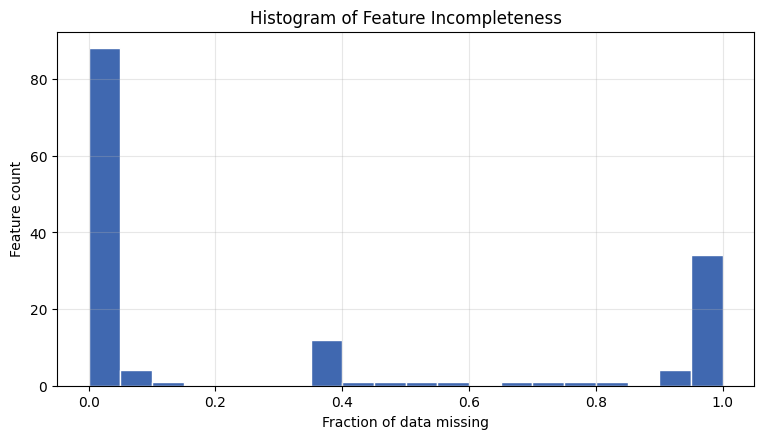

Features with >80% missing (dropped): 39 | with <20% missing: 93


In [5]:
import pandas as pd
import time
import os
import numpy as np

def load_raw(csv_path):
    t0 = time.time(); null_counts = None; n_rows = 0; kept = []
    for k, ch in enumerate(pd.read_csv(csv_path, chunksize=CHUNKSIZE, low_memory=False, dtype=str)):
        null_counts = ch.isna().sum() if null_counts is None else null_counts.add(ch.isna().sum(), fill_value=0)
        n_rows += len(ch)
        ok = ch["loan_status"].isin(["Fully Paid", "Charged Off"])
        kept.append(ch.loc[ok, [c for c in SELECTED_COLS if c in ch.columns]])
        if k % 5 == 0: print(f"  chunk {k}: {n_rows:,} rows read ({time.time()-t0:.0f}s)")
    return pd.concat(kept, ignore_index=True), (null_counts / n_rows), n_rows, len(null_counts)

raw_sel, miss_frac, n_raw_rows, n_raw_cols = load_raw(CSV_PATH)
print(f"\nRaw file: {n_raw_rows:,} rows x {n_raw_cols} columns (paper: >2.26 million records, 151 variables)")
vc = raw_sel["loan_status"].value_counts()
print("Resolved loans -> Fully Paid: {:,} | Charged Off: {:,}   (paper: 1,076,751 / 268,559, ratio 80:20)".format(
      vc.get("Fully Paid", 0), vc.get("Charged Off", 0)))

# --- Fig. 4: histogram of the fraction of missing data per feature
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.hist(miss_frac.values, bins=20, color="#4068b0", edgecolor="white")
ax.set_title("Histogram of Feature Incompleteness"); ax.set_xlabel("Fraction of data missing"); ax.set_ylabel("Feature count")
ax.grid(alpha=.3); show_save(fig, "Fig4_missing_value_histogram")
print("Features with >80% missing (dropped):", int((miss_frac > 0.8).sum()), "| with <20% missing:", int((miss_frac < 0.2).sum()))

In [6]:
from google.colab import drive
drive.mount('/content/drive')

import os

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for file in files:
        if file.lower() == 'accepted_2007_to_2018q4.csv':
            print("CSV found:", os.path.join(root, file))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CSV found: /content/drive/MyDrive/accepted_2007_to_2018Q4.csv


## 5. Cleaning and base feature engineering

Operations in this stage: duplicate removal; >80% missingness rule; target coding; term/date parsing; issue-year extraction; credit-line-year extraction; employment-length parsing; zip truncation; numeric conversion; mortgage-account group-mean imputation using `total_acc`; remaining median/mode imputation; and domain-informed outlier handling. Test data are not used to fit these transformations.

In [7]:
def clean(raw):
    df = raw.copy()
    n0 = len(df)
    df = df.drop_duplicates().reset_index(drop=True)                                        # duplicate removal
    n_dup = n0 - len(df)
    # drop selected columns with >80% missing (none expected after pre-selection, kept for faithfulness)
    miss = df.isna().mean(); df = df.drop(columns=miss[miss > 0.8].index.tolist())
    # --- data type standardisation
    df["loan_status"] = (df["loan_status"] == "Fully Paid").astype(int)                     # 1: Fully Paid, 0: Charged Off
    df["term"] = df["term"].astype(str).str.extract(r"(\d+)")[0].astype(float)              # " 36 months" -> 36
    df["issue_d"] = pd.to_datetime(df["issue_d"], format="%b-%Y", errors="coerce")
    df["issue_year"] = df["issue_d"].dt.year
    df["issue_d_num"] = df["issue_year"] + (df["issue_d"].dt.month - 1) / 12                # numeric issue date (Fig. 5/6)
    df["earliest_cr_line"] = pd.to_datetime(df["earliest_cr_line"], format="%b-%Y", errors="coerce").dt.year.astype(float)
    df["emp_length"] = (df["emp_length"].astype(str).str.replace("< 1", "0").str.extract(r"(\d+)")[0].astype(float))
    df["zip_code"] = df["zip_code"].astype(str).str[:3]                                      # 3-digit zip (Sect. 3.2.3.2)
    num_cols = ["loan_amnt","int_rate","installment","annual_inc","dti","open_acc","pub_rec","revol_bal","revol_util",
                "total_acc","recoveries","mort_acc","pub_rec_bankruptcies"]
    for c in num_cols: df[c] = pd.to_numeric(df[c], errors="coerce")
    df = df.dropna(subset=["issue_year", "term"])
    # --- missing-value imputation
    # group-wise mean imputation for mort_acc using total_acc as proxy (Sect. 3.2.1)
    grp = df.groupby("total_acc")["mort_acc"].transform("mean")
    df["mort_acc"] = df["mort_acc"].fillna(grp).fillna(df["mort_acc"].median())
    for c in num_cols + ["emp_length", "earliest_cr_line"]:
        df[c] = df[c].fillna(df[c].median())
    for c in ["emp_title", "title"]: df[c] = df[c].fillna("Unknown")
    for c in df.columns:                                       # remaining categorical columns -> mode (works for object and pandas>=3 str dtype)
        if not (pd.api.types.is_numeric_dtype(df[c]) or pd.api.types.is_datetime64_any_dtype(df[c])):
            df[c] = df[c].fillna(df[c].mode().iloc[0])
    # --- outlier removal with domain thresholds (not z-scores)
    n1 = len(df)
    for c, (lo, hi) in OUTLIER_RULES.items(): df = df[(df[c] >= lo) & (df[c] <= hi)]
    df = df[df["earliest_cr_line"] >= 1946]
    df["pub_rec_bankruptcies"] = df["pub_rec_bankruptcies"].clip(upper=9)
    print(f"Cleaning: duplicates removed={n_dup:,} | outliers removed={n1-len(df):,} | final rows={len(df):,}")
    return df.reset_index(drop=True)

df_all = clean(raw_sel); del raw_sel; gc.collect()
print("Class distribution after cleaning:\n", df_all["loan_status"].value_counts().rename({1: "Fully Paid", 0: "Charged Off"}))
print("Loans per issue year:\n", df_all["issue_year"].value_counts().sort_index().to_string())

Cleaning: duplicates removed=0 | outliers removed=19,855 | final rows=1,325,455
Class distribution after cleaning:
 loan_status
Fully Paid     1060219
Charged Off     265236
Name: count, dtype: int64
Loans per issue year:
 issue_year
2007       247
2008      1554
2009      4674
2010     11442
2011     21560
2012     53033
2013    133763
2014    220757
2015    370573
2016    288325
2017    165179
2018     54348


## 6. Correlation analysis — Figures 5 and 6

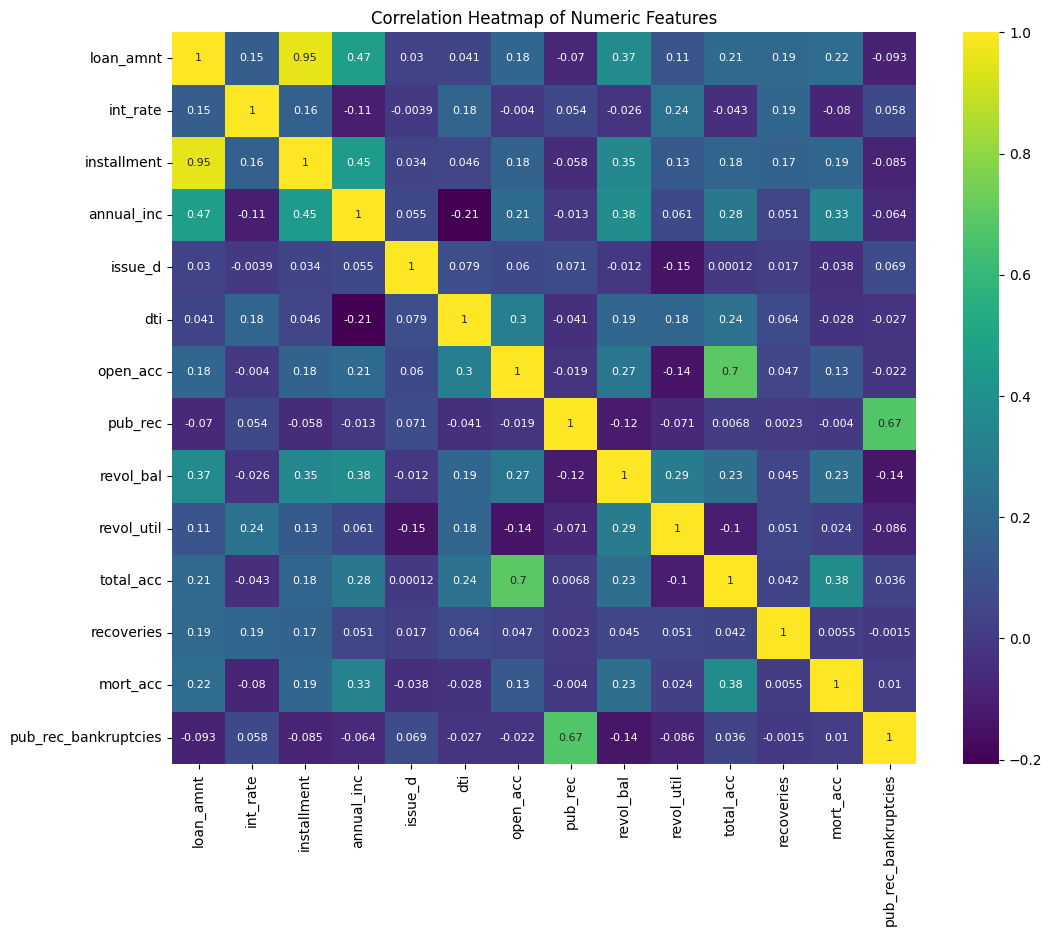

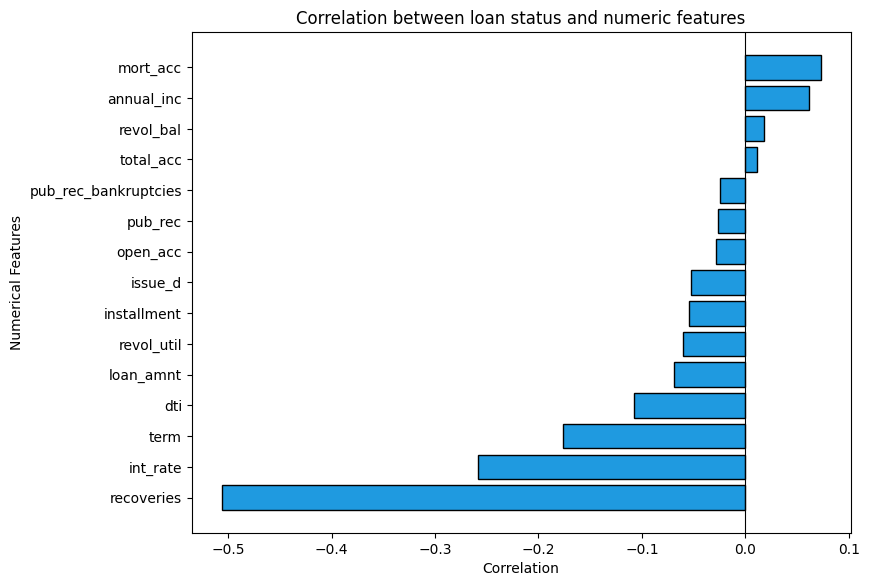

Paper (Fig. 6): negative = recoveries (-0.44), int_rate (-0.29), term (-0.18); positive = mort_acc, annual_inc
mort_acc                0.073
annual_inc              0.061
revol_bal               0.018
total_acc               0.011
pub_rec_bankruptcies   -0.025
pub_rec                -0.027
open_acc               -0.029
issue_d                -0.052
installment            -0.055
revol_util             -0.060
loan_amnt              -0.069
dti                    -0.108
term                   -0.177
int_rate               -0.259
recoveries             -0.506


In [8]:
# %%
heat_cols = ["loan_amnt","int_rate","installment","annual_inc","issue_d_num","dti","open_acc","pub_rec","revol_bal",
             "revol_util","total_acc","recoveries","mort_acc","pub_rec_bankruptcies"]
corr = df_all[heat_cols].corr()
fig, ax = plt.subplots(figsize=(12, 9.5))
sns.heatmap(corr.rename(index={"issue_d_num": "issue_d"}, columns={"issue_d_num": "issue_d"}), annot=True, fmt=".2g",
            cmap="viridis", ax=ax, annot_kws={"size": 8})
ax.set_title("Correlation Heatmap of Numeric Features"); show_save(fig, "Fig5_correlation_heatmap")

tcorr = df_all[heat_cols + ["term", "loan_status"]].corr()["loan_status"].drop("loan_status")
tcorr = tcorr.rename({"issue_d_num": "issue_d"}).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8.5, 6.5))
ax.barh(tcorr.index[::-1], tcorr.values[::-1], color="#1f9ae0", edgecolor="black")
ax.axvline(0, color="k", lw=.8); ax.set_xlabel("Correlation"); ax.set_ylabel("Numerical Features")
ax.set_title("Correlation between loan status and numeric features"); show_save(fig, "Fig6_correlation_with_target")
print("Paper (Fig. 6): negative = recoveries (-0.44), int_rate (-0.29), term (-0.18); positive = mort_acc, annual_inc")
print(tcorr.round(3).to_string())

## 7. CatBoost feature importance — Figure 7

The paper's reported top-22 features are the default reproduction set. Set `FEATURE_SELECTION = "catboost"` in the configuration cell only if you explicitly want to test a newly computed top-22 list; that is a separate variation and can change the results.

In [9]:
%pip install catboost pgmpy scikit-learn imbalanced-learn pandas numpy matplotlib seaborn networkx

CatBoost top-22 : ['recoveries', 'title', 'sub_grade', 'emp_title', 'int_rate', 'initial_list_status', 'term', 'mort_acc', 'annual_inc', 'loan_amnt', 'dti', 'home_ownership', 'zip_code', 'emp_length', 'verification_status', 'installment', 'earliest_cr_line', 'addr_state', 'purpose', 'pub_rec', 'open_acc', 'total_acc']
Overlap with the paper's 22 features (Fig. 7): 18/22 | missing from CatBoost top-22: ['application_type', 'pub_rec_bankruptcies', 'revol_bal', 'revol_util']
Feature set used downstream (FEATURE_SELECTION='paper'): ['int_rate', 'recoveries', 'annual_inc', 'term', 'loan_amnt', 'sub_grade', 'revol_bal', 'dti', 'revol_util', 'mort_acc', 'purpose', 'installment', 'home_ownership', 'addr_state', 'open_acc', 'earliest_cr_line', 'verification_status', 'total_acc', 'application_type', 'pub_rec', 'pub_rec_bankruptcies', 'initial_list_status']


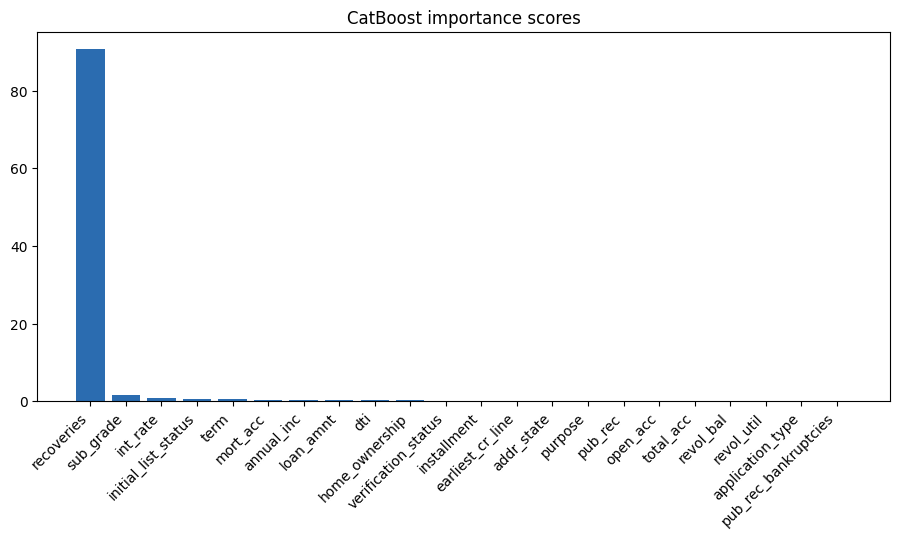

In [10]:
# %%
from catboost import CatBoostClassifier

def catboost_importance(df):
    cand = [c for c in SELECTED_COLS if c not in ("loan_status", "issue_d", "grade")]     # 'grade' dropped (redundant with sub_grade)
    X = df[cand].copy(); y = df["loan_status"]
    cat_cols = [c for c in cand if not pd.api.types.is_numeric_dtype(X[c])]
    for c in cat_cols: X[c] = LabelEncoder().fit_transform(X[c].astype(str))
    cb = CatBoostClassifier(iterations=CATBOOST_ITER, depth=6, learning_rate=0.1, loss_function="Logloss",
                            random_seed=RANDOM_STATE, verbose=False, thread_count=-1)
    cb.fit(X, y, cat_features=cat_cols)
    imp = pd.Series(cb.get_feature_importance(), index=cand).sort_values(ascending=False)
    return imp

cb_imp = catboost_importance(df_all)
save_table(cb_imp.to_frame("importance"), "CatBoost_importance_all_candidates")
cb_top22 = cb_imp.head(N_FINAL_FEATURES).index.tolist()
print("CatBoost top-22 :", cb_top22)
print("Overlap with the paper's 22 features (Fig. 7): {}/22 | missing from CatBoost top-22: {}".format(
      len(set(cb_top22) & set(PAPER_22)), sorted(set(PAPER_22) - set(cb_top22))))
FINAL_FEATURES = PAPER_22 if FEATURE_SELECTION == "paper" else cb_top22
print(f"Feature set used downstream (FEATURE_SELECTION='{FEATURE_SELECTION}'):", FINAL_FEATURES)

show = cb_imp.reindex(PAPER_22).sort_values(ascending=False) if FEATURE_SELECTION == "paper" else cb_imp.head(22)
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.bar(show.index, show.values, color="#2b6cb0"); ax.set_title("CatBoost importance scores")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right"); show_save(fig, "Fig7_catboost_importance_top22")

## 8. Build baseline and macro-enriched datasets (feature engineering + temporal split)

Baseline features contain borrower/loan attributes only. Macro-enriched data are merged by `addr_state` and `issue_year`, then the three macro predictors are added. Because the macro reference tables begin in 2008, the enriched data naturally exclude 2007 rows. The 2018 test set is held out and never resampled.

### 8A. Resampling utilities and checkpoint helper

RUS and SMOTENC are applied per issue-year on training rows only. `term` is treated as categorical during SMOTENC. Checkpoints are written under this notebook's new versioned output directory.

In [11]:
# %%
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTENC
import time
import pandas as pd
import numpy as np

def balance_by_year(train_df, features, strategy):
    parts = []
    start_time = time.time()

    years = sorted(train_df["issue_year"].dropna().unique())
    print(f"{strategy}: processing {len(years)} years", flush=True)

    for year in years:
        year_start = time.time()
        g = train_df.loc[train_df["issue_year"] == year, features + ["loan_status"]]

        X = g[features].copy()
        y = g["loan_status"].astype(int).to_numpy()

        n_min = int(min((y == 0).sum(), (y == 1).sum()))

        if n_min < 2:
            print(f"  Skipping {year}: too few minority-class rows", flush=True)
            continue

        print(
            f"  Year {year}: input={len(g):,}, "
            f"class 0={(y == 0).sum():,}, class 1={(y == 1).sum():,}",
            flush=True
        )

        if strategy == "RUS":
            Xr, yr = RandomUnderSampler(
                random_state=RANDOM_STATE
            ).fit_resample(X, y)

        elif strategy == "SMOTENC":
            Xs = X.copy()

            if "term" in Xs.columns:
                Xs["term"] = Xs["term"].astype(int).astype(str)

            cat_pos = [
                features.index(c)
                for c in CAT_SMOTE
                if c in features
            ]

            sampler = SMOTENC(
                categorical_features=cat_pos,
                k_neighbors=min(5, n_min - 1),
                random_state=RANDOM_STATE
            )

            Xr, yr = sampler.fit_resample(Xs, y)

            Xr = pd.DataFrame(Xr, columns=features)

            for c in features:
                if c not in CAT_SMOTE:
                    Xr[c] = pd.to_numeric(Xr[c], errors="raise").astype(float)

            if "term" in Xr.columns:
                Xr["term"] = Xr["term"].astype(float)

        else:
            raise ValueError(
                f"Unknown strategy: {strategy!r}. Use 'RUS' or 'SMOTENC'."
            )

        out = pd.DataFrame(Xr, columns=features)
        out["loan_status"] = np.asarray(yr).astype(int)
        out["issue_year"] = year
        parts.append(out)

        print(
            f"  Year {year}: output={len(out):,}, "
            f"elapsed={time.time() - year_start:.1f}s",
            flush=True
        )

        del X, Xr, yr, out, g

    if not parts:
        raise ValueError("No yearly groups produced a balanced dataset.")

    result = pd.concat(parts, ignore_index=True)

    print(
        f"{strategy} complete: {len(result):,} rows; "
        f"total elapsed={time.time() - start_time:.1f}s",
        flush=True
    )

    return result

### 8B. Create the train/test sets and macro-enriched feature set

In [12]:
keep = FINAL_FEATURES + ["loan_status", "issue_year"]
base_df = df_all[keep + [c for c in ["addr_state"] if c not in keep]]
train_base = base_df[base_df.issue_year.isin(TRAIN_YEARS)]
test_base  = base_df[base_df.issue_year == TEST_YEAR].reset_index(drop=True)
print(f"Baseline: train(2007-2017)={len(train_base):,}  test(2018)={len(test_base):,}")

enr_df = add_macro(base_df)
train_enr = enr_df[enr_df.issue_year.isin(TRAIN_YEARS)]
test_enr  = enr_df[enr_df.issue_year == TEST_YEAR].reset_index(drop=True)
ENR_FEATURES = FINAL_FEATURES + MACRO3
print(f"Enriched: train(2008-2017)={len(train_enr):,}  test(2018)={len(test_enr):,}")

# Persist split datasets so downstream cells can be rerun without rebuilding this step.
train_base.to_pickle(os.path.join(CACHE_DIR, "train_base.pkl"), compression="gzip")
test_base.to_pickle(os.path.join(CACHE_DIR, "test_base.pkl"), compression="gzip")
train_enr.to_pickle(os.path.join(CACHE_DIR, "train_macro_enriched.pkl"), compression="gzip")
test_enr.to_pickle(os.path.join(CACHE_DIR, "test_macro_enriched.pkl"), compression="gzip")
print("Saved baseline/macro train-test splits in:", CACHE_DIR)

Baseline: train(2007-2017)=1,271,107  test(2018)=54,348
Enriched: train(2008-2017)=1,270,860  test(2018)=54,348
Saved baseline/macro train-test splits in: /content/drive/MyDrive/LendingClub_Reproduction/outputs_paper_faithful_v7_structured/cache


### 8C. Random undersampling (RUS) — training set only

This creates the RUS baseline training set for Table 2. The 2018 test set remains unchanged.

In [13]:
import os
import pickle
import pandas as pd

def _cache(name, fn):
    """Reuse a saved checkpoint or compute and save it if missing."""

    os.makedirs(CACHE_DIR, exist_ok=True)
    path = os.path.join(CACHE_DIR, name + ".pkl")

    if os.path.exists(path):
        try:
            with open(path, "rb") as f:
                obj = pickle.load(f)

            if isinstance(obj, pd.DataFrame) and "loan_status" in obj.columns:
                print(f"REUSING SAVED CHECKPOINT: {path} | shape={obj.shape}")
                return obj

            print("Cache has unexpected schema; recomputing:", path)

        except Exception as exc:
            print("Cache could not be read; recomputing:", repr(exc))

    print(f"Computing checkpoint: {name}", flush=True)
    obj = fn()

    tmp = path + ".tmp"

    with open(tmp, "wb") as f:
        pickle.dump(obj, f, protocol=pickle.HIGHEST_PROTOCOL)

    os.replace(tmp, path)

    print(f"Saved checkpoint: {path} | shape={obj.shape}", flush=True)

    return obj

In [14]:
t0 = time.time()
print("Balancing: RUS (baseline) ...")
rus_base = _cache("rus_base", lambda: balance_by_year(train_base, FINAL_FEATURES, "RUS"))
print(f"RUS training rows = {len(rus_base):,} (paper reports 567,119; differences can arise from data/version/cleaning details)")
print(rus_base["loan_status"].value_counts().rename({0:"Charged Off/default", 1:"Fully Paid"}))

Balancing: RUS (baseline) ...
REUSING SAVED CHECKPOINT: /content/drive/MyDrive/LendingClub_Reproduction/outputs_paper_faithful_v7_structured/cache/rus_base.pkl | shape=(513360, 24)
RUS training rows = 513,360 (paper reports 567,119; differences can arise from data/version/cleaning details)
loan_status
Charged Off/default    256680
Fully Paid             256680
Name: count, dtype: int64


### 8D. SMOTENC oversampling — baseline and macro-enriched training sets

SMOTENC creates synthetic minority observations for mixed categorical/numeric features. It is run separately for baseline and macro-enriched training data; no synthetic samples are created from the 2018 test set.

In [15]:
print("Balancing: SMOTENC (baseline) ...")
smote_base = _cache("smote_base", lambda: balance_by_year(train_base, FINAL_FEATURES, "SMOTENC"))
print(f"SMOTENC baseline training rows = {len(smote_base):,} (paper reports 2,080,917)")
print(smote_base["loan_status"].value_counts().rename({0:"Charged Off/default", 1:"Fully Paid"}))

print("Balancing: SMOTENC (macro-enriched) ...")
smote_enr = _cache("smote_enr", lambda: balance_by_year(train_enr, ENR_FEATURES, "SMOTENC"))
print(f"SMOTENC macro-enriched training rows = {len(smote_enr):,}; elapsed={time.time()-t0:.0f}s")
print(smote_enr["loan_status"].value_counts().rename({0:"Charged Off/default", 1:"Fully Paid"}))

Balancing: SMOTENC (baseline) ...
REUSING SAVED CHECKPOINT: /content/drive/MyDrive/LendingClub_Reproduction/outputs_paper_faithful_v7_structured/cache/smote_base.pkl | shape=(2028854, 24)
SMOTENC baseline training rows = 2,028,854 (paper reports 2,080,917)
loan_status
Fully Paid             1014427
Charged Off/default    1014427
Name: count, dtype: int64
Balancing: SMOTENC (macro-enriched) ...
REUSING SAVED CHECKPOINT: /content/drive/MyDrive/LendingClub_Reproduction/outputs_paper_faithful_v7_structured/cache/smote_enr.pkl | shape=(2028446, 27)
SMOTENC macro-enriched training rows = 2,028,446; elapsed=16s
loan_status
Fully Paid             1014223
Charged Off/default    1014223
Name: count, dtype: int64


## 9. Machine-learning model setup — Table 1

Nine model families are listed in Table 1. The same 2018 test set is used for all models, and the feature transformer is fitted on the training data only.

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

TABLE1 = pd.DataFrame([
    ["Logistic Regression","Linear","Default parameters"],["Decision Tree","Tree-based","Tree depth: 10"],
    ["K-Nearest Neighbors","Instance-based","Number of neighbors: 20"],["Random Forest","Ensemble (bagging)","20 trees, depth = 10"],
    ["Gaussian Naive Bayes","Probabilistic","Default parameters"],["LightGBM","Gradient boosting","75 trees, depth = 4, LR = 0.1"],
    ["XGBoost","Gradient boosting","100 trees, depth = 5, LR = 0.08"],["Gradient Boosting","Gradient boosting","100 trees, depth = 5, LR = 0.08"],
    ["Neural Network","Deep learning","Hidden layer architecture: (512, 256, 128)"]], columns=["Algorithm","Family","Key Hyperparameters"])
save_table(TABLE1, "Table1_ML_configuration", index=False); print("Table 1\n", TABLE1.to_string(index=False))

Table 1
            Algorithm             Family                        Key Hyperparameters
 Logistic Regression             Linear                         Default parameters
       Decision Tree         Tree-based                             Tree depth: 10
 K-Nearest Neighbors     Instance-based                    Number of neighbors: 20
       Random Forest Ensemble (bagging)                       20 trees, depth = 10
Gaussian Naive Bayes      Probabilistic                         Default parameters
            LightGBM  Gradient boosting              75 trees, depth = 4, LR = 0.1
             XGBoost  Gradient boosting            100 trees, depth = 5, LR = 0.08
   Gradient Boosting  Gradient boosting            100 trees, depth = 5, LR = 0.08
      Neural Network      Deep learning Hidden layer architecture: (512, 256, 128)


## 10. ML evaluation helpers

Metrics follow the paper's convention: positive class for Tables 2–6 is Fully Paid (`1`); the BN inference also reports default as state `s1` / code `0`. This is important when comparing class metrics and ROC curves.

In [17]:
def make_models():
    return {
      "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=30,
        max_depth=3,
        learning_rate=0.08,
        random_state=RANDOM_STATE
      ),
      "LightGBM": LGBMClassifier(n_estimators=75, max_depth=4, learning_rate=0.1, random_state=RANDOM_STATE, verbose=-1),
      "XGBoost": XGBClassifier(n_estimators=100, max_depth=5, learning_rate=0.08, random_state=RANDOM_STATE,
                               eval_metric="logloss", n_jobs=-1),
      "Random Forest": RandomForestClassifier(n_estimators=20, max_depth=10, random_state=RANDOM_STATE, n_jobs=-1),
      "Logistic Regression": LogisticRegression(max_iter=1000),
      "Neural Network": MLPClassifier(hidden_layer_sizes=(512, 256, 128), early_stopping=True, batch_size=1024,
                                      max_iter=60, random_state=RANDOM_STATE),
      "Decision Tree": DecisionTreeClassifier(max_depth=10, random_state=RANDOM_STATE),
      "K Nearest Neighbors": KNeighborsClassifier(n_neighbors=20, n_jobs=-1),
      "Gaussian Naive Bayes": GaussianNB()}

def ks_stat(y, p):
    fpr, tpr, _ = roc_curve(y, p); return float(np.max(tpr - fpr))
def ece_score(y, p, bins=10):
    edges = np.linspace(0, 1, bins + 1); idx = np.clip(np.digitize(p, edges[1:-1]), 0, bins - 1); e = 0.0
    for b in range(bins):
        m = idx == b
        if m.any(): e += m.mean() * abs(y[m].mean() - p[m].mean())
    return float(e)
def evaluate(y, p, thr=0.5):
    """Positive class = Fully Paid (1), as in Tables 2-6 (precision ~0.88, recall ~0.97). p = P(Fully Paid)."""
    y = np.asarray(y).astype(int); p = np.asarray(p, float); pred = (p >= thr).astype(int)
    return {"Accuracy": accuracy_score(y, pred), "ROC-AUC": roc_auc_score(y, p), "Precision": precision_score(y, pred, zero_division=0),
            "Recall": recall_score(y, pred), "F1-Score": f1_score(y, pred), "KS_Statistic": ks_stat(y, p),
            "Brier Score": brier_score_loss(y, p), "ECE": ece_score(y, p)}

def _dense(a): return a.toarray() if hasattr(a, "toarray") else np.asarray(a)


def run_ml(train_bal, test_df, features, tag):
    """
    Train only the requested models and reuse any valid cached results.

    KNN uses a reproducible subset of the training rows when the
    number of rows exceeds KNN_TRAIN_CAP.
    """

    import os
    import json
    import time
    import numpy as np
    import pandas as pd

    from sklearn.compose import ColumnTransformer
    from sklearn.preprocessing import MinMaxScaler, OneHotEncoder

    # --------------------------------------------------
    # 1. Identify categorical and numerical features
    # --------------------------------------------------
    cat = [c for c in CAT_FEATS if c in features]
    num = [c for c in features if c not in cat]

    try:
        ohe = OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=True
        )
    except TypeError:
        ohe = OneHotEncoder(
            handle_unknown="ignore",
            sparse=True
        )

    # Fit preprocessing on training data only
    pre = ColumnTransformer([
        ("num", MinMaxScaler(), num),
        ("cat", ohe, cat)
    ])

    print("Preparing training and test matrices...", flush=True)

    Xtr = pre.fit_transform(
        train_bal[features]
    ).astype(np.float32)

    ytr = train_bal["loan_status"].to_numpy(dtype=int)

    Xte = pre.transform(
        test_df[features]
    ).astype(np.float32)

    yte = test_df["loan_status"].to_numpy(dtype=int)

    print(
        f"[{tag}] design matrix: "
        f"train {Xtr.shape}, test {Xte.shape}",
        flush=True
    )

    # --------------------------------------------------
    # 2. Select the models to run
    # --------------------------------------------------
    res = {}

    wanted = [
        m.strip()
        for m in ML_MODELS_ONLY.split(",")
        if m.strip()
    ] or MODEL_ORDER

    models = make_models()

    print("Models selected:", wanted, flush=True)

    # --------------------------------------------------
    # 3. Run selected models
    # --------------------------------------------------
    for name, mdl in models.items():

        if name not in wanted:
            continue

        ck = os.path.join(
            CACHE_DIR,
            f"ml_{tag}_{name.replace(' ', '_')}.json"
        )

        # Reuse cached metrics when available
        if os.path.exists(ck):
            try:
                with open(ck, "r") as f:
                    cached = json.load(f)

                if all(metric in cached for metric in METRICS):
                    res[name] = cached

                    print(
                        f"  {name}: loaded from checkpoint",
                        flush=True
                    )
                    continue

                print(
                    f"  {name}: checkpoint incomplete; rerunning",
                    flush=True
                )

            except (OSError, json.JSONDecodeError) as exc:
                print(
                    f"  {name}: could not read checkpoint: {exc}",
                    flush=True
                )

        t0 = time.time()

        X_fit = Xtr
        y_fit = ytr

        # ----------------------------------------------
        # 4. K-Nearest Neighbors
        # ----------------------------------------------
        if name == "K Nearest Neighbors":

            cap = KNN_TRAIN_CAP

            if cap and Xtr.shape[0] > cap:
                rng = np.random.RandomState(RANDOM_STATE)

                ii = rng.choice(
                    Xtr.shape[0],
                    size=cap,
                    replace=False
                )

                X_fit = Xtr[ii]
                y_fit = ytr[ii]

                print(
                    f"  KNN training subset: "
                    f"{X_fit.shape[0]:,} of {Xtr.shape[0]:,} rows",
                    flush=True
                )

            print("  Fitting KNN...", flush=True)

            mdl.fit(X_fit, y_fit)

            print("  Predicting with KNN...", flush=True)

            predictions = []

            for start in range(0, Xte.shape[0], 2000):
                end = min(start + 2000, Xte.shape[0])

                batch = Xte[start:end]

                probabilities = mdl.predict_proba(batch)[:, 1]
                predictions.append(probabilities)

                print(
                    f"    Predicted {end:,}/{Xte.shape[0]:,} test rows",
                    flush=True
                )

            p = np.concatenate(predictions)

        # ----------------------------------------------
        # 5. Gaussian Naive Bayes
        # ----------------------------------------------
        elif name == "Gaussian Naive Bayes":

            print(
                "  Training Gaussian Naive Bayes in batches...",
                flush=True
            )

            classes = np.array([0, 1])

            for start in range(0, X_fit.shape[0], 200_000):
                end = min(start + 200_000, X_fit.shape[0])

                print(
                    f"    Training rows {start:,} to {end:,}",
                    flush=True
                )

                # GaussianNB needs dense input
                batch = _dense(X_fit[start:end])

                mdl.partial_fit(
                    batch,
                    y_fit[start:end],
                    classes=classes
                )

            print(
                "  Predicting with Gaussian Naive Bayes...",
                flush=True
            )

            test_predictions = []

            for start in range(0, Xte.shape[0], 5000):
                end = min(start + 5000, Xte.shape[0])

                batch = _dense(Xte[start:end])

                probabilities = mdl.predict_proba(batch)[:, 1]
                test_predictions.append(probabilities)

                print(
                    f"    Predicted {end:,}/{Xte.shape[0]:,} test rows",
                    flush=True
                )

            p = np.concatenate(test_predictions)

        # ----------------------------------------------
        # 6. Any other requested model
        # ----------------------------------------------
        else:
            print(f"  Fitting {name}...", flush=True)

            mdl.fit(X_fit, y_fit)

            p = mdl.predict_proba(Xte)[:, 1]

        # ----------------------------------------------
        # 7. Evaluate and save metrics
        # ----------------------------------------------
        print(f"  Evaluating {name}...", flush=True)

        metrics = evaluate(yte, p)
        res[name] = metrics

        os.makedirs(CACHE_DIR, exist_ok=True)

        tmp = ck + ".tmp"

        with open(tmp, "w") as f:
            json.dump(metrics, f, indent=2)

        os.replace(tmp, ck)

        print(
            f"  {name:22s} "
            f"AUC={metrics['ROC-AUC']:.3f} "
            f"Acc={metrics['Accuracy']:.3f} "
            f"({time.time() - t0:.0f}s)",
            flush=True
        )

    # --------------------------------------------------
    # 8. Build results table
    # --------------------------------------------------
    out = (
        pd.DataFrame(res)
        .T
        .reindex([m for m in MODEL_ORDER if m in res])
    )

    out = out[METRICS]

    return out



## 11. Table 2 — ML models trained with RUS

In [18]:
if RUN_ML:
    T2 = run_ml(rus_base, test_base, FINAL_FEATURES, "T2_rus")
    save_table(T2.round(3), "Table2_ML_undersampling")
    compare_with_paper(T2, PAPER_T2, "Table 2 (Under-sampling)")
else:
    T2 = None
    print("RUN_ML=0 -> Table 2 skipped")

Preparing training and test matrices...
[T2_rus] design matrix: train (513360, 128), test (54348, 128)
Models selected: ['Gradient Boosting', 'LightGBM', 'XGBoost', 'Random Forest', 'Logistic Regression', 'Neural Network', 'Decision Tree', 'K Nearest Neighbors', 'Gaussian Naive Bayes']
  Gradient Boosting: loaded from checkpoint
  LightGBM: loaded from checkpoint
  XGBoost: loaded from checkpoint
  Random Forest: loaded from checkpoint
  Logistic Regression: loaded from checkpoint
  Neural Network: loaded from checkpoint
  Decision Tree: loaded from checkpoint
  K Nearest Neighbors: loaded from checkpoint
  Gaussian Naive Bayes: loaded from checkpoint

===== Table 2 (Under-sampling): REPRODUCED =====
                      Accuracy  ROC-AUC  Precision  Recall  F1-Score  KS_Statistic  Brier Score    ECE
Gradient Boosting        0.861    0.770      0.887   0.957     0.921         0.376        0.114  0.110
LightGBM                 0.867    0.763      0.885   0.968     0.925         0.365  

In [19]:
import os

print("Output directory:", OUT_DIR)

for root, dirs, files in os.walk(OUT_DIR):
    for name in files:
        if "Table2_ML_undersampling" in name or "T2_rus" in name:
            print("Found:", os.path.join(root, name))

Output directory: /content/drive/MyDrive/LendingClub_Reproduction/outputs_paper_faithful_v7_structured
Found: /content/drive/MyDrive/LendingClub_Reproduction/outputs_paper_faithful_v7_structured/tables/Table2_ML_undersampling.csv
Found: /content/drive/MyDrive/LendingClub_Reproduction/outputs_paper_faithful_v7_structured/cache/ml_T2_rus_Gradient_Boosting.json
Found: /content/drive/MyDrive/LendingClub_Reproduction/outputs_paper_faithful_v7_structured/cache/ml_T2_rus_LightGBM.json
Found: /content/drive/MyDrive/LendingClub_Reproduction/outputs_paper_faithful_v7_structured/cache/ml_T2_rus_XGBoost.json
Found: /content/drive/MyDrive/LendingClub_Reproduction/outputs_paper_faithful_v7_structured/cache/ml_T2_rus_Random_Forest.json
Found: /content/drive/MyDrive/LendingClub_Reproduction/outputs_paper_faithful_v7_structured/cache/ml_T2_rus_Logistic_Regression.json
Found: /content/drive/MyDrive/LendingClub_Reproduction/outputs_paper_faithful_v7_structured/cache/ml_T2_rus_Neural_Network.json
Found: /

In [20]:
import os
import json

cache_dir = os.path.join(OUT_DIR, "cache")

for filename in sorted(os.listdir(cache_dir)):
    if filename.startswith("ml_T2_rus_") and filename.endswith(".json"):
        path = os.path.join(cache_dir, filename)
        print(f"\n--- {filename} ---")

        with open(path, "r") as f:
            data = json.load(f)

        print(data)


--- ml_T2_rus_Decision_Tree.json ---
{'Accuracy': 0.8535732685655406, 'ROC-AUC': 0.7506164465257706, 'Precision': 0.8877228940356631, 'Recall': 0.9458420684835779, 'F1-Score': 0.9158613689708401, 'KS_Statistic': 0.350330459432149, 'Brier Score': 0.11911711451831203, 'ECE': 0.10785958071089628}

--- ml_T2_rus_Gaussian_Naive_Bayes.json ---
{'Accuracy': 0.8067086185324207, 'ROC-AUC': 0.7541741493805436, 'Precision': 0.8958338007313845, 'Recall': 0.8719863731656184, 'F1-Score': 0.8837492391965917, 'KS_Statistic': 0.3605552406981064, 'Brier Score': 0.1828486904359764, 'ECE': 0.18234491827177607}

--- ml_T2_rus_Gradient_Boosting.json ---
{'Accuracy': 0.8608596452491352, 'ROC-AUC': 0.7703016042885462, 'Precision': 0.8869276547508198, 'Recall': 0.956848357791754, 'F1-Score': 0.9205622203080026, 'KS_Statistic': 0.3762486793138901, 'Brier Score': 0.1143373846284201, 'ECE': 0.10968192631662295}

--- ml_T2_rus_K_Nearest_Neighbors.json ---
{'Accuracy': 0.6662802679031428, 'ROC-AUC': 0.679971489372

## 12. Table 3 — ML models trained with SMOTENC (baseline features)

In [21]:
if RUN_ML:
    T3 = run_ml(smote_base, test_base, FINAL_FEATURES, "T3_smote")
    save_table(T3.round(3), "Table3_ML_SMOTENC")
    compare_with_paper(T3, PAPER_T3, "Table 3 (SMOTENC)")
else:
    T3 = None
    print("RUN_ML=0 ->  Table 3 skipped")

Preparing training and test matrices...
[T3_smote] design matrix: train (2028854, 128), test (54348, 128)
Models selected: ['Gradient Boosting', 'LightGBM', 'XGBoost', 'Random Forest', 'Logistic Regression', 'Neural Network', 'Decision Tree', 'K Nearest Neighbors', 'Gaussian Naive Bayes']
  Gradient Boosting: loaded from checkpoint
  LightGBM: loaded from checkpoint
  XGBoost: loaded from checkpoint
  Random Forest: loaded from checkpoint
  Logistic Regression: loaded from checkpoint
  Neural Network: loaded from checkpoint
  Decision Tree: loaded from checkpoint
  K Nearest Neighbors: loaded from checkpoint
  Gaussian Naive Bayes: loaded from checkpoint

===== Table 3 (SMOTENC): REPRODUCED =====
                      Accuracy  ROC-AUC  Precision  Recall  F1-Score  KS_Statistic  Brier Score    ECE
Gradient Boosting        0.882    0.748      0.877   1.000     0.934         0.342        0.104  0.064
LightGBM                 0.882    0.749      0.877   1.000     0.934         0.343      

In [22]:
import os
import time

print("Runtime connected")
print("CPU cores:", os.cpu_count())

try:
    import psutil
    print("RAM used:", round(psutil.virtual_memory().percent, 1), "%")
    print("Available RAM:", round(
        psutil.virtual_memory().available / (1024**3), 2
    ), "GB")
except ImportError:
    print("Install psutil if needed: !pip install psutil")

Runtime connected
CPU cores: 2
RAM used: 50.0 %
Available RAM: 6.34 GB


In [23]:
import os
import json

CACHE_DIR = (
    "/content/drive/MyDrive/LendingClub_Reproduction/"
    "outputs_paper_faithful_v7_structured/cache"
)

print("Checking model checkpoints...\n")

if os.path.isdir(CACHE_DIR):
    for filename in sorted(os.listdir(CACHE_DIR)):
        if filename.endswith(".json") and filename.startswith("ml_"):
            path = os.path.join(CACHE_DIR, filename)
            try:
                with open(path, "r") as f:
                    data = json.load(f)
                print("SAVED:", filename, "| Metrics:", list(data.keys()))
            except Exception as e:
                print("INVALID:", filename, "|", e)
else:
    print("Cache directory not found:", CACHE_DIR)

Checking model checkpoints...

SAVED: ml_T2_rus_Decision_Tree.json | Metrics: ['Accuracy', 'ROC-AUC', 'Precision', 'Recall', 'F1-Score', 'KS_Statistic', 'Brier Score', 'ECE']
SAVED: ml_T2_rus_Gaussian_Naive_Bayes.json | Metrics: ['Accuracy', 'ROC-AUC', 'Precision', 'Recall', 'F1-Score', 'KS_Statistic', 'Brier Score', 'ECE']
SAVED: ml_T2_rus_Gradient_Boosting.json | Metrics: ['Accuracy', 'ROC-AUC', 'Precision', 'Recall', 'F1-Score', 'KS_Statistic', 'Brier Score', 'ECE']
SAVED: ml_T2_rus_K_Nearest_Neighbors.json | Metrics: ['Accuracy', 'ROC-AUC', 'Precision', 'Recall', 'F1-Score', 'KS_Statistic', 'Brier Score', 'ECE']
SAVED: ml_T2_rus_LightGBM.json | Metrics: ['Accuracy', 'ROC-AUC', 'Precision', 'Recall', 'F1-Score', 'KS_Statistic', 'Brier Score', 'ECE']
SAVED: ml_T2_rus_Logistic_Regression.json | Metrics: ['Accuracy', 'ROC-AUC', 'Precision', 'Recall', 'F1-Score', 'KS_Statistic', 'Brier Score', 'ECE']
SAVED: ml_T2_rus_Neural_Network.json | Metrics: ['Accuracy', 'ROC-AUC', 'Precision', 'R

In [24]:
import os
import json

CACHE_DIR = (
    "/content/drive/MyDrive/LendingClub_Reproduction/"
    "outputs_paper_faithful_v7_structured/cache"
)

print("SMOTE model checkpoints:\n")

for filename in sorted(os.listdir(CACHE_DIR)):
    if filename.startswith("ml_T3_smote_") and filename.endswith(".json"):
        path = os.path.join(CACHE_DIR, filename)

        try:
            with open(path, "r") as f:
                metrics = json.load(f)

            required = {
                "Accuracy", "ROC-AUC", "Precision", "Recall",
                "F1-Score", "KS_Statistic", "Brier Score", "ECE"
            }

            status = "VALID" if required.issubset(metrics.keys()) else "INCOMPLETE"
            print(status, filename)

        except Exception as e:
            print("INVALID", filename, str(e))

print("\nCheckpoint check complete.")

SMOTE model checkpoints:

VALID ml_T3_smote_Decision_Tree.json
VALID ml_T3_smote_Gaussian_Naive_Bayes.json
VALID ml_T3_smote_Gradient_Boosting.json
VALID ml_T3_smote_K_Nearest_Neighbors.json
VALID ml_T3_smote_LightGBM.json
VALID ml_T3_smote_Logistic_Regression.json
VALID ml_T3_smote_Neural_Network.json
VALID ml_T3_smote_Random_Forest.json
VALID ml_T3_smote_XGBoost.json

Checkpoint check complete.


In [25]:
import os

print("Cache directory:", CACHE_DIR)

files_to_check = [
    "rus_base.pkl",
    "smote_base.pkl",
    "smote_enr.pkl",
]

for name in files_to_check:
    path = os.path.join(CACHE_DIR, name)
    if os.path.exists(path):
        print(f"✅ SAVED: {name} ({os.path.getsize(path) / (1024**2):.1f} MB)")
    else:
        print(f"❌ NOT SAVED: {name}")

Cache directory: /content/drive/MyDrive/LendingClub_Reproduction/outputs_paper_faithful_v7_structured/cache
✅ SAVED: rus_base.pkl (83.3 MB)
✅ SAVED: smote_base.pkl (319.4 MB)
✅ SAVED: smote_enr.pkl (365.7 MB)


## 13. Table 4 — ML models with macroeconomic features

In [26]:
if RUN_ML:
    T4 = run_ml(smote_enr, test_enr, ENR_FEATURES, "T4_enriched")
    save_table(T4.round(3), "Table4_ML_macro_enriched")
    compare_with_paper(T4, PAPER_T4, "Table 4 (Macro-enriched)")
    ens = [m for m in ["Gradient Boosting","LightGBM","XGBoost","Random Forest"] if m in T3.index and m in T4.index]
    if ens:
        print("\nEnsemble average (GB, LGBM, XGB, RF) baseline -> enriched (paper: AUC 0.751->0.768, KS 0.351->0.376)")
        print("AUC {:.3f} -> {:.3f} | KS {:.3f} -> {:.3f}".format(T3.loc[ens,"ROC-AUC"].mean(), T4.loc[ens,"ROC-AUC"].mean(), T3.loc[ens,"KS_Statistic"].mean(), T4.loc[ens,"KS_Statistic"].mean()))
else:
    T4 = None
    print("RUN_ML=0 -> Table 4 skipped")

Preparing training and test matrices...
[T4_enriched] design matrix: train (2028446, 131), test (54348, 131)
Models selected: ['Gradient Boosting', 'LightGBM', 'XGBoost', 'Random Forest', 'Logistic Regression', 'Neural Network', 'Decision Tree', 'K Nearest Neighbors', 'Gaussian Naive Bayes']
  Gradient Boosting: loaded from checkpoint
  LightGBM: loaded from checkpoint
  XGBoost: loaded from checkpoint
  Random Forest: loaded from checkpoint
  Logistic Regression: loaded from checkpoint
  Fitting Neural Network...
  Evaluating Neural Network...
  Neural Network         AUC=0.675 Acc=0.498 (5559s)
  Fitting Decision Tree...
  Evaluating Decision Tree...
  Decision Tree          AUC=0.747 Acc=0.881 (39s)
  Fitting KNN...
  Predicting with KNN...
    Predicted 2,000/54,348 test rows
    Predicted 4,000/54,348 test rows
    Predicted 6,000/54,348 test rows
    Predicted 8,000/54,348 test rows
    Predicted 10,000/54,348 test rows
    Predicted 12,000/54,348 test rows
    Predicted 14,000/5

## 14. Bayesian-network discretisation and engine

Continuous BN variables are discretised using 1-D K-means with bin counts transcribed from Table A.7. The engine includes Tabu Search structure learning (BIC, add/remove/reverse moves, tabu list, MI-based initial arcs), comparison learners for Table A.8, EM parameter estimation, prediction, likelihood-weighted inference, sensitivity analysis, and mutual information.

In [27]:
# %%
TARGET = "loan_status"

def state_labels(n):
    return [f"s{i+1:02d}" if n >= 10 else f"s{i+1}" for i in range(n)]

class BNDiscretizer:
    def __init__(self, nodes): self.nodes = nodes
    def fit(self, df):
        self.kind, self.edges, self.labels, self.lo_hi, self.cats = {}, {}, {}, {}, {}
        rs = np.random.RandomState(RANDOM_STATE)
        for c in self.nodes:
            if c == TARGET:
                self.kind[c] = "target"; self.labels[c] = ["s1", "s2"]        # s1 = default (Charged Off), s2 = Fully Paid
            elif c == "term":
                self.kind[c] = "term"; self.labels[c] = ["s1", "s2"]          # s1 = 36 months, s2 = 60 months
            elif c == "pub_rec_bankruptcies":
                self.kind[c] = "bank"; self.labels[c] = state_labels(10)
            elif c in K_BINS:
                x = df[c].values.astype(float); self.lo_hi[c] = (float(np.min(x)), float(np.max(x)))
                xs = x if len(x) <= KMEANS_FIT_ROWS else x[rs.choice(len(x), KMEANS_FIT_ROWS, replace=False)]
                k = min(K_BINS[c], len(np.unique(xs)))
                cen = np.sort(KMeans(n_clusters=k, n_init=3, random_state=RANDOM_STATE).fit(xs.reshape(-1, 1)).cluster_centers_.ravel())
                self.kind[c] = "cont"; self.edges[c] = (cen[:-1] + cen[1:]) / 2; self.labels[c] = state_labels(k)
            else:
                self.kind[c] = "cat"; self.cats[c] = sorted(df[c].astype(str).unique()); self.labels[c] = self.cats[c]
        self.cards = [len(self.labels[c]) for c in self.nodes]
        self.mode_code = {}
        return self
    def transform(self, df):
        out = np.zeros((len(df), len(self.nodes)), dtype=np.int32)
        for j, c in enumerate(self.nodes):
            k = self.kind[c]
            if k == "target": v = df[c].astype(int).values                      # 1 paid -> code 1, 0 default -> code 0
            elif k == "term": v = (df[c].values >= 48).astype(int)
            elif k == "bank": v = np.clip(df[c].values.astype(int), 0, 9)
            elif k == "cont": v = np.searchsorted(self.edges[c], df[c].values.astype(float), side="right")
            else:
                m = {s: i for i, s in enumerate(self.cats[c])}; raw = df[c].astype(str).map(m)
                if c not in self.mode_code: self.mode_code[c] = int(raw.mode().iloc[0])
                v = raw.fillna(self.mode_code[c]).astype(int).values                # unseen category -> most frequent state
            out[:, j] = v
        return out
    def table_a7(self):
        rows = []
        for c in self.nodes:
            if c in self.edges:
                b = np.concatenate([[self.lo_hi[c][0]], self.edges[c], [self.lo_hi[c][1]]])
                rng_ = ", ".join(f"[{b[i]:.2f}, {b[i+1]:.2f})" for i in range(len(b) - 1))
                rows.append([c, rng_, ",".join(map(str, range(len(b) - 1)))])
            elif self.kind[c] in ("term", "bank"):
                rows.append([c, "Categorical", ",".join(map(str, range(len(self.labels[c]))))])
        return pd.DataFrame(rows, columns=["Variable", "Value Ranges", "Discretized Categories"]).sort_values("Variable")

# ---------------------------------------------------------------- the network
class DiscreteBN:
    def __init__(self, names, cards, parents, target=TARGET):
        self.names, self.cards, self.d = list(names), list(cards), len(names)
        self.parents = [list(p) for p in parents]; self.T = self.names.index(target)
        self.children = [[j for j in range(self.d) if i in self.parents[j]] for i in range(self.d)]
        g = nx.DiGraph(); g.add_nodes_from(range(self.d))
        for j in range(self.d):
            for i in self.parents[j]: g.add_edge(i, j)
        assert nx.is_directed_acyclic_graph(g), "structure has a cycle"
        self.order = list(nx.topological_sort(g))
    def pa_index(self, codes, i):
        idx = np.zeros(len(codes), dtype=np.int64)
        for p in self.parents[i]: idx = idx * self.cards[p] + codes[:, p].astype(np.int64)
        return idx
    # ---- Parameter learning: Expectation-Maximisation, uniform initialisation, log-likelihood convergence
    def fit_em(self, codes, ess=BDEU_ESS, max_iter=30, tol=1e-6, verbose=False):
        n = len(codes); self.cfg_ids, self.tables, self.marg, self.em_history = [], [], [], []
        stats = []
        for i in range(self.d):                                  # sufficient statistics (data are fully observed,
            r = self.cards[i]; idx = self.pa_index(codes, i)     # so the E-step expected counts equal observed counts)
            u, c = np.unique(idx * r + codes[:, i], return_counts=True)
            ucfg, inv = np.unique(u // r, return_inverse=True)
            cnt = np.zeros((len(ucfg), r)); cnt[inv, u % r] = c
            stats.append((ucfg, cnt)); self.marg.append(np.bincount(codes[:, i], minlength=r) / n)
            self.cfg_ids.append(ucfg); self.tables.append(np.full((len(ucfg), r), 1.0 / r))     # uniform start
        ll_old = -np.inf
        for it in range(1, max_iter + 1):
            ll = 0.0
            for i in range(self.d):                              # E-step -> expected counts ; M-step -> new CPTs
                ucfg, cnt = stats[i]; r = self.cards[i]
                q = float(np.prod([self.cards[p] for p in self.parents[i]])) if self.parents[i] else 1.0
                a_jk = ess / (q * r)
                self.tables[i] = (cnt + a_jk) / (cnt.sum(1, keepdims=True) + r * a_jk)
                ll += float((cnt * np.log(self.tables[i])).sum())
            self.em_history.append(ll)
            if verbose: print(f"    EM iter {it}: log-likelihood = {ll:,.2f}")
            if abs(ll - ll_old) < tol * max(1.0, abs(ll)): break
            ll_old = ll
        return self
    def cpt_rows(self, i, codes):
        idx = self.pa_index(codes, i); ids = self.cfg_ids[i]
        pos = np.minimum(np.searchsorted(ids, idx), len(ids) - 1); found = ids[pos] == idx
        return np.where(found[:, None], self.tables[i][pos], self.marg[i][None, :])    # unseen parent set -> node marginal
    def predict_paid(self, codes):
        """Exact P(loan_status = Fully Paid | all other nodes) via the Markov blanket."""
        codes = codes.copy(); n = len(codes); blanket = [self.T] + self.children[self.T]; lp = np.zeros((n, 2)); ar = np.arange(n)
        for y in (0, 1):
            codes[:, self.T] = y
            for v in blanket:
                lp[:, y] += np.log(np.clip(self.cpt_rows(v, codes)[ar, codes[:, v]], 1e-12, 1.0))
        z = lp - lp.max(1, keepdims=True); p = np.exp(z); return p[:, 1] / p.sum(1)
    def sample(self, n, evidence=None, rng=None):
        """Ancestral sampling with likelihood weighting for evidence {node_index: state}."""
        evidence = evidence or {}; rng = rng or np.random.default_rng(RANDOM_STATE)
        codes = np.zeros((n, self.d), dtype=np.int32); w = np.ones(n); ar = np.arange(n)
        for i in self.order:
            rows = self.cpt_rows(i, codes)
            if i in evidence:
                codes[:, i] = evidence[i]; w *= rows[:, evidence[i]]
            else:
                u = rng.random(n); codes[:, i] = np.minimum((rows.cumsum(1) < u[:, None]).sum(1), self.cards[i] - 1)
        return codes, w
    def edges(self): return [(self.names[i], self.names[j]) for j in range(self.d) for i in self.parents[j]]

# ---------------------------------------------------------------- structure scoring + search
class ScoreCache:
    def __init__(self, codes, cards, kind="bic", ess=1.0):
        self.c, self.cards, self.kind, self.ess, self.n, self.cache = codes, cards, kind, ess, len(codes), {}
    def local(self, i, pa):
        key = (i, pa)
        if key in self.cache: return self.cache[key]
        r = self.cards[i]; idx = np.zeros(self.n, dtype=np.int64); q = 1.0
        for p in pa: idx = idx * self.cards[p] + self.c[:, p]; q *= self.cards[p]
        u, cnt = np.unique(idx * r + self.c[:, i], return_counts=True)
        uj, inv = np.unique(u // r, return_inverse=True); Nj = np.bincount(inv, weights=cnt)
        if self.kind == "bic":
            s = float((cnt * np.log(cnt / Nj[inv])).sum()) - 0.5 * np.log(self.n) * (r - 1) * q
        else:                                                                   # BDeu
            a_j, a_jk = self.ess / q, self.ess / (q * r)
            s = float((gammaln(a_j) - gammaln(a_j + Nj)).sum() + (gammaln(a_jk + cnt) - gammaln(a_jk)).sum())
        self.cache[key] = s; return s

def _reach(ch, src, dst, skip=None):
    stack, seen = [src], {src}
    while stack:
        x = stack.pop()
        for y in ch[x]:
            if skip == (x, y): continue
            if y == dst: return True
            if y not in seen: seen.add(y); stack.append(y)
    return False

def local_search(d, cache, forbid, max_indeg, init_edges=(), mode="tabu", tabu_len=20, patience=12, max_iter=150,
                 restarts=0, seed=0, label=""):
    rng = np.random.default_rng(seed)
    par = [set() for _ in range(d)]; ch = [set() for _ in range(d)]
    for (i, j) in init_edges:
        if (i, j) not in forbid and len(par[j]) < max_indeg and not _reach(ch, j, i): par[j].add(i); ch[i].add(j)
    L = lambda j, s: cache.local(j, tuple(sorted(s)))
    def run(par, ch, mode):
        cur = sum(L(j, par[j]) for j in range(d)); best = cur; best_par = [set(p) for p in par]; tabu = deque(maxlen=tabu_len); since = 0
        for it in range(max_iter):
            moves = []
            for j in range(d):
                base = L(j, par[j])
                for i in range(d):
                    if i == j: continue
                    if i in par[j]:
                        moves.append((L(j, par[j] - {i}) - base, "rem", i, j))
                        if (j, i) not in forbid and len(par[i]) < max_indeg and not _reach(ch, i, j, skip=(i, j)):
                            moves.append((L(j, par[j] - {i}) - base + L(i, par[i] | {j}) - L(i, par[i]), "rev", i, j))
                    elif (i, j) not in forbid and len(par[j]) < max_indeg and not _reach(ch, j, i):
                        moves.append((L(j, par[j] | {i}) - base, "add", i, j))
            moves.sort(key=lambda m: -m[0]); chosen = None
            for m in moves:
                if mode == "hill" and m[0] <= 1e-9: break
                if (m[1], m[2], m[3]) in tabu and not (cur + m[0] > best + 1e-9): continue
                chosen = m; break
            if chosen is None: break
            dlt, kind, i, j = chosen
            if kind == "add": par[j].add(i); ch[i].add(j); tabu.append(("rem", i, j))
            elif kind == "rem": par[j].discard(i); ch[i].discard(j); tabu.append(("add", i, j))
            else: par[j].discard(i); ch[i].discard(j); par[i].add(j); ch[j].add(i); tabu.append(("rev", j, i))
            cur += dlt
            if cur > best + 1e-9: best, best_par, since = cur, [set(p) for p in par], 0
            else:
                since += 1
                if since >= patience: break
        return best, best_par
    best, best_par = run(par, ch, mode)
    for r in range(restarts):                                       # random restarts (Bayesian-search learner)
        p2 = [set(p) for p in best_par]; c2 = [set() for _ in range(d)]
        for j in range(d):
            for i in p2[j]: c2[i].add(j)
        for _ in range(8):
            i, j = rng.choice(d, 2, replace=False)
            if i in p2[j]: p2[j].discard(i); c2[i].discard(j)
            elif (i, j) not in forbid and len(p2[j]) < max_indeg and not _reach(c2, j, i): p2[j].add(i); c2[i].add(j)
        s2, bp2 = run(p2, c2, mode)
        if s2 > best: best, best_par = s2, bp2
    print(f"    [{label}] best {cache.kind.upper()} score = {best:,.1f} | arcs = {sum(len(p) for p in best_par)}")
    return [sorted(p) for p in best_par]

def mutual_info(codes, i, j, ci, cj):
    n = len(codes); joint = np.bincount(codes[:, i].astype(np.int64) * cj + codes[:, j], minlength=ci * cj).reshape(ci, cj) / n
    pi, pj = joint.sum(1, keepdims=True), joint.sum(0, keepdims=True); m = joint > 0
    return float((joint[m] * np.log(joint[m] / (pi @ pj)[m])).sum())

def learn_pc(codes, names, cards, rows):
    from pgmpy.estimators import PC
    sub = pd.DataFrame(codes[rows], columns=names).astype("category")
    est = PC(data=sub)
    try: dag = est.estimate(variant="stable", ci_test="chi_square", return_type="dag", significance_level=0.01,
                            max_cond_vars=3, show_progress=False)
    except Exception:
        pdag = est.estimate(variant="stable", ci_test="chi_square", return_type="pdag", significance_level=0.01,
                            max_cond_vars=3, show_progress=False); dag = pdag.to_dag()
    par = [[] for _ in names]
    for (a, b) in dag.edges(): par[names.index(b)].append(names.index(a))
    return par

# ---------------------------------------------------------------- plots used for BN figures
def draw_graph(ax, names, edges, fc, bold=(), fontsize=9, edge_color="#222", lw=.8):
    """Circular layout; each arrow runs between the borders of the two node boxes so heads touch the nodes."""
    G = nx.DiGraph(); G.add_nodes_from(names); pos = nx.circular_layout(G); ax.set_axis_off(); tx = {}
    ax.set_xlim(-1.4, 1.4); ax.set_ylim(-1.2, 1.2)
    for n_ in names:
        x, y = pos[n_]
        tx[n_] = ax.text(x, y, n_, ha="center", va="center", fontsize=fontsize, fontweight="bold" if n_ in bold else "normal",
                         bbox=dict(boxstyle="round,pad=0.35", fc=fc(n_), ec="#555"), zorder=5)
    fig = ax.figure; fig.canvas.draw(); inv = ax.transData.inverted(); half = {}
    for n_, t in tx.items():
        bb = t.get_bbox_patch().get_window_extent(fig.canvas.get_renderer()); (x0, y0), (x1, y1) = inv.transform([[bb.x0, bb.y0], [bb.x1, bb.y1]])
        half[n_] = ((x1 - x0) / 2 + .004, (y1 - y0) / 2 + .004)
    def edge_pt(c, other, h):
        dx, dy = other[0] - c[0], other[1] - c[1]; t = min(h[0] / abs(dx) if dx else np.inf, h[1] / abs(dy) if dy else np.inf)
        return (c[0] + dx * t, c[1] + dy * t)
    for (a, b) in edges:
        ax.annotate("", xy=edge_pt(pos[b], pos[a], half[b]), xytext=edge_pt(pos[a], pos[b], half[a]), zorder=2,
                    arrowprops=dict(arrowstyle="-|>", color=edge_color, lw=lw, shrinkA=0, shrinkB=0, mutation_scale=12))

def plot_structure(bn, title, fname):
    fig, ax = plt.subplots(figsize=(13, 11))
    draw_graph(ax, bn.names, bn.edges(), lambda n_: "#fbe3c4", bold=(TARGET,))
    ax.set_title(title, fontsize=12); show_save(fig, fname)

def plot_marginals(bn, disc, marg, title, fname, ncols=5):
    names = bn.names; n = len(names); nrows = int(np.ceil(n / ncols))
    fig, axs = plt.subplots(nrows, ncols, figsize=(3.3 * ncols, 2.6 * nrows)); axs = np.atleast_1d(axs).ravel()
    for k, nm in enumerate(names):
        ax = axs[k]; p = marg[k] * 100; lab = disc.labels[nm]
        ax.barh(range(len(p))[::-1], p, color="#222"); ax.set_yticks(range(len(p))[::-1]); ax.set_xlim(0, 105)
        ax.set_yticklabels([f"{l}  {v:.3g}" for l, v in zip(lab, p)], fontsize=5.5 if len(p) > 12 else 7)
        ax.set_title(nm, fontsize=9, fontweight="bold", backgroundcolor="#e8d9bf"); ax.tick_params(axis="x", labelsize=6)
    for ax in axs[n:]: ax.axis("off")
    fig.suptitle(title, y=1.0); fig.tight_layout(); show_save(fig, fname)

def weighted_marginals(bn, codes, w):
    return [np.bincount(codes[:, i], weights=w, minlength=bn.cards[i]) / w.sum() for i in range(bn.d)]

def p_default(bn, evidence, n, seed=0):
    codes, w = bn.sample(n, evidence, np.random.default_rng(seed)); return float(w[codes[:, bn.T] == 0].sum() / w.sum())

def sensitivity(bn, n, seed=1, min_count=30):
    """d P(loan_status=s1) / d theta_{x|u} for every CPT parameter, siblings co-varying proportionally
    (Kjaerulff & van der Gaag, 2000). In conditional form the derivative is
        P(u) * [ P(y | x, u) - P(y | u, X != x) ]            (always bounded by P(u) <= 1)
    and is estimated from n samples of the network; cells supported by fewer than `min_count` samples are ignored."""
    codes, _ = bn.sample(n, None, np.random.default_rng(seed)); isdef = codes[:, bn.T] == 0; recs = []
    for i in range(bn.d):
        r = bn.cards[i]; idx = bn.pa_index(codes, i)
        u_all, c_all = np.unique(idx * r + codes[:, i], return_counts=True)
        u_d, c_d = np.unique(idx[isdef] * r + codes[isdef, i], return_counts=True)
        dxu = np.zeros(len(u_all)); dxu[np.searchsorted(u_all, u_d)] = c_d                       # default counts per (u, x)
        cfg = u_all // r; x = u_all % r; ucfg, inv = np.unique(cfg, return_inverse=True)
        n_u = np.bincount(inv, weights=c_all)[inv]; d_u = np.bincount(inv, weights=dxu)[inv]    # counts per u
        n_comp = n_u - c_all; d_comp = d_u - dxu
        ok = (c_all >= min_count) & (n_comp >= min_count)
        with np.errstate(divide="ignore", invalid="ignore"):
            der = (n_u / n) * (dxu / c_all - d_comp / n_comp)
        for k in np.where(ok & np.isfinite(der))[0]: recs.append((i, int(cfg[k]), int(x[k]), float(der[k])))
    return float(isdef.mean()), recs

def decode_cfg(bn, i, cfg):
    vals = []
    for p in reversed(bn.parents[i]): vals.append(cfg % bn.cards[p]); cfg //= bn.cards[p]
    return list(reversed(vals))

def param_label(bn, disc, i, cfg, x):
    s = f"{bn.names[i]}={disc.labels[bn.names[i]][x]}"
    if bn.parents[i]:
        pv = decode_cfg(bn, i, cfg)
        s += " | " + ", ".join(f"{bn.names[p]}={disc.labels[bn.names[p]][v]}" for p, v in zip(bn.parents[i], pv))
    return s

def plot_tornado(bn, disc, P, recs, title, fname, top=10, delta=0.05):
    top_recs = sorted(recs, key=lambda r: -abs(r[3]))[:top]
    fig, ax = plt.subplots(figsize=(11, 5.6)); lo_all, hi_all = [], []
    for k, (i, cfg, x, der) in enumerate(top_recs):
        lo, hi = P - abs(der) * delta, P + abs(der) * delta; lo_all.append(lo); hi_all.append(hi); y = len(top_recs) - k
        left_col, right_col = ("#1faa1f", "#d62020") if der > 0 else ("#d62020", "#1faa1f")
        ax.barh(y, P - lo, left=lo, height=.5, color=left_col, edgecolor="k", lw=.6); ax.barh(y, hi - P, left=P, height=.5, color=right_col, edgecolor="k", lw=.6)
        ax.text(P, y + .33, f"{k+1}: {param_label(bn, disc, i, cfg, x)}", ha="center", fontsize=8)
    ax.axvline(P, color="teal", lw=1); ax.set_yticks([]); ax.set_ylim(.2, len(top_recs) + .9)
    ax.set_title(f"Sensitivity for loan_status=s1\nCurrent value: {P:.6f}  Reachable range: [{min(lo_all):.6f} .. {max(hi_all):.6f}]  (parameter varied by +/-{delta})", fontsize=10)
    show_save(fig, fname); return [(param_label(bn, disc, i, cfg, x), der) for (i, cfg, x, der) in top_recs]

def plot_colored_network(bn, recs, title, fname):
    score = np.zeros(bn.d)
    for (i, cfg, x, der) in recs: score[i] = max(score[i], abs(der))
    sc = score / (score.max() + 1e-12); cm = plt.cm.Reds
    col = {bn.names[i]: ("#d9d9d9" if i == bn.T else cm(0.12 + 0.88 * sc[i])) for i in range(bn.d)}
    fig, ax = plt.subplots(figsize=(12, 10.5))
    draw_graph(ax, bn.names, bn.edges(), lambda n_: col[n_], fontsize=8.5, edge_color="#1c1c9c", lw=.7)
    ax.set_title(title + "  (deeper red = higher max |dP(default)/dparameter|)"); show_save(fig, fname)
    return pd.Series(score, index=bn.names).sort_values(ascending=False)

def plot_mi(codes, bn, title, fname, top=10):
    mi = {bn.names[i]: mutual_info(codes, i, bn.T, bn.cards[i], 2) for i in range(bn.d) if i != bn.T}
    s = pd.Series(mi).sort_values(ascending=False).head(top)
    fig, ax = plt.subplots(figsize=(9, 4.6)); ax.plot(range(len(s)), s.values, "-o", color="#2b6cb0")
    ax.set_xticks(range(len(s))); ax.set_xticklabels(s.index, rotation=45, ha="right"); ax.set_title("Mutual Information")
    ax.grid(alpha=.3); ax.set_ylabel("MI with loan_status (nats)"); show_save(fig, fname); return s

def plot_roc(y_paid, p_paid, title, fname):
    y_def = 1 - np.asarray(y_paid); fpr, tpr, _ = roc_curve(y_def, 1 - np.asarray(p_paid)); auc = roc_auc_score(y_def, 1 - np.asarray(p_paid))
    fig, ax = plt.subplots(figsize=(6.4, 6)); ax.plot(fpr, tpr, color="green", lw=1.8); ax.plot([0, 1], [0, 1], color="#bbb", lw=1)
    ax.set_xlabel("False positive rate (1 - specificity)"); ax.set_ylabel("True positive rate (sensitivity)")
    ax.set_title(f"ROC curve for loan_status=s1 (AUC={auc:.6f})"); ax.grid(alpha=.4); show_save(fig, fname)

## 15. Learn baseline and macro-enriched BNs; Tables A.7–A.8, Figures 8–11, Table 5, Figures A.1–A.2, Table 6

This cell learns the primary Tabu Search network for each feature set, compares structure learners for the baseline model, fits BN parameters with EM, evaluates the 2018 test set, and writes the network diagrams and prediction metrics.

[baseline] learning structures on 200,000 rows ...
    [Tabu] best BIC score = -4,022,767.8 | arcs = 39
    [Bayesian search] best BDEU score = -4,004,020.3 | arcs = 39
    [PC] arcs = 22
[baseline] done in 1072s
[baseline] saved fitted BN bundle: /content/drive/MyDrive/LendingClub_Reproduction/outputs_paper_faithful_v7_structured/cache/bn_baseline_complete.pkl
[macro_enriched] learning structures on 200,000 rows ...
    [Tabu] best BIC score = -4,861,493.6 | arcs = 47
[macro_enriched] done in 21s
[macro_enriched] saved fitted BN bundle: /content/drive/MyDrive/LendingClub_Reproduction/outputs_paper_faithful_v7_structured/cache/bn_macro_enriched_complete.pkl

===== Table A.8 (structure learning algorithms): REPRODUCED =====
                   AUC     KS  Brier score
Tabu search      0.724  0.317        0.124
Bayesian search  0.724  0.317        0.124
PC               0.653  0.255        0.176
Naive Bayes      0.739  0.327        0.160
----- Table A.8 (structure learning algorithms): PAP

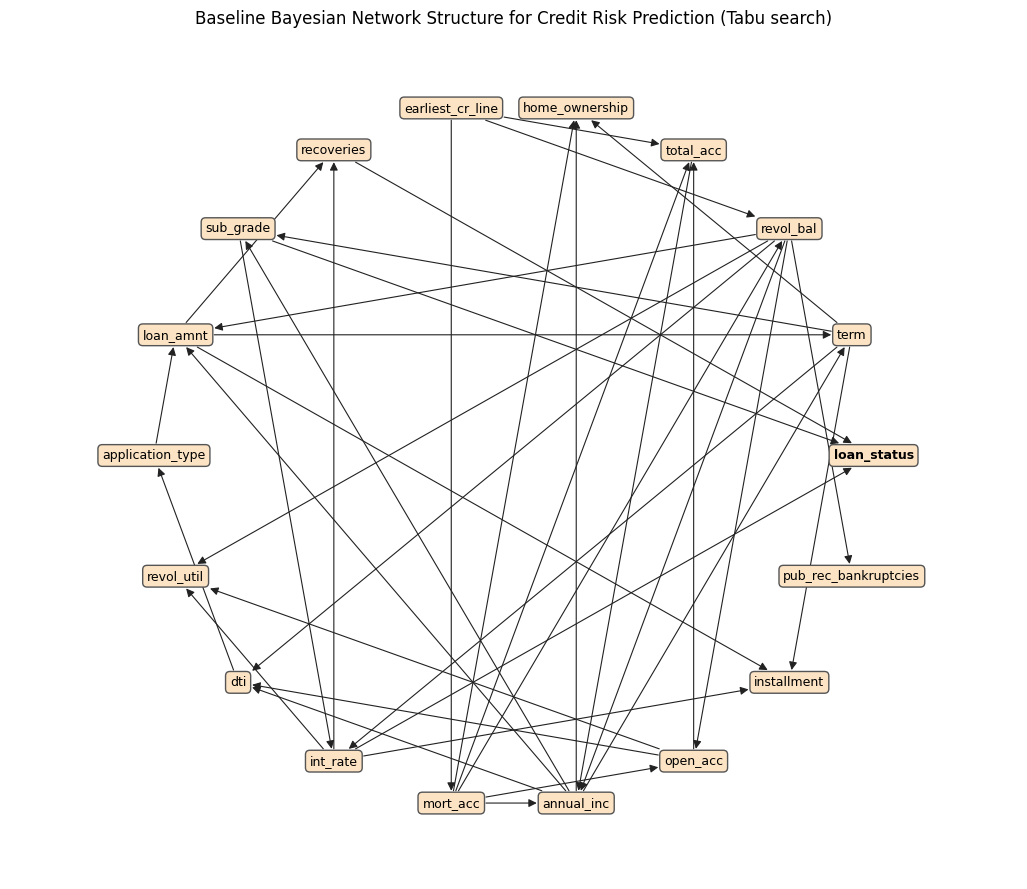

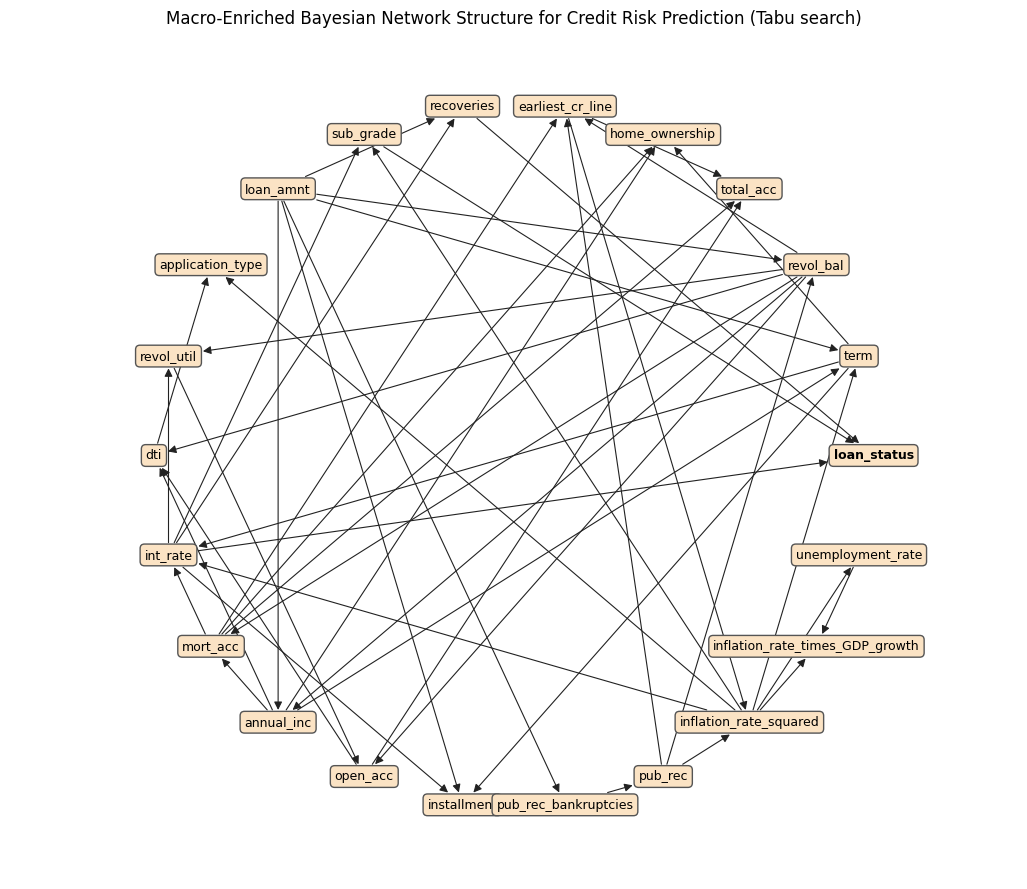

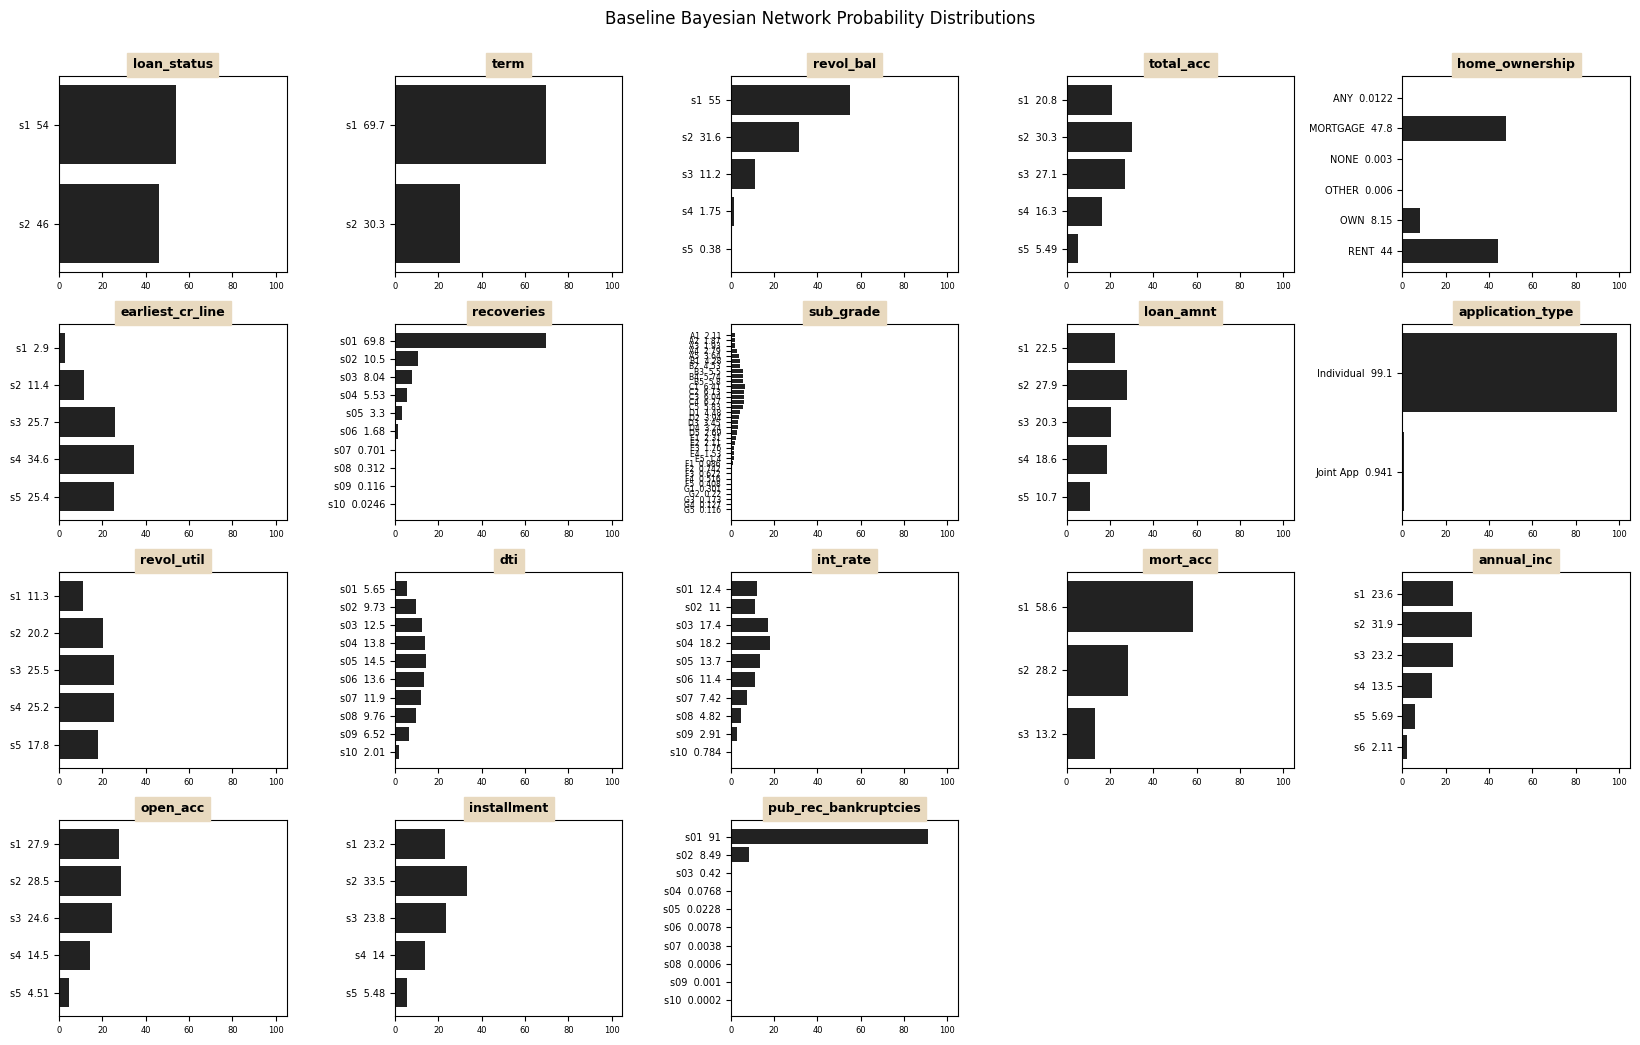

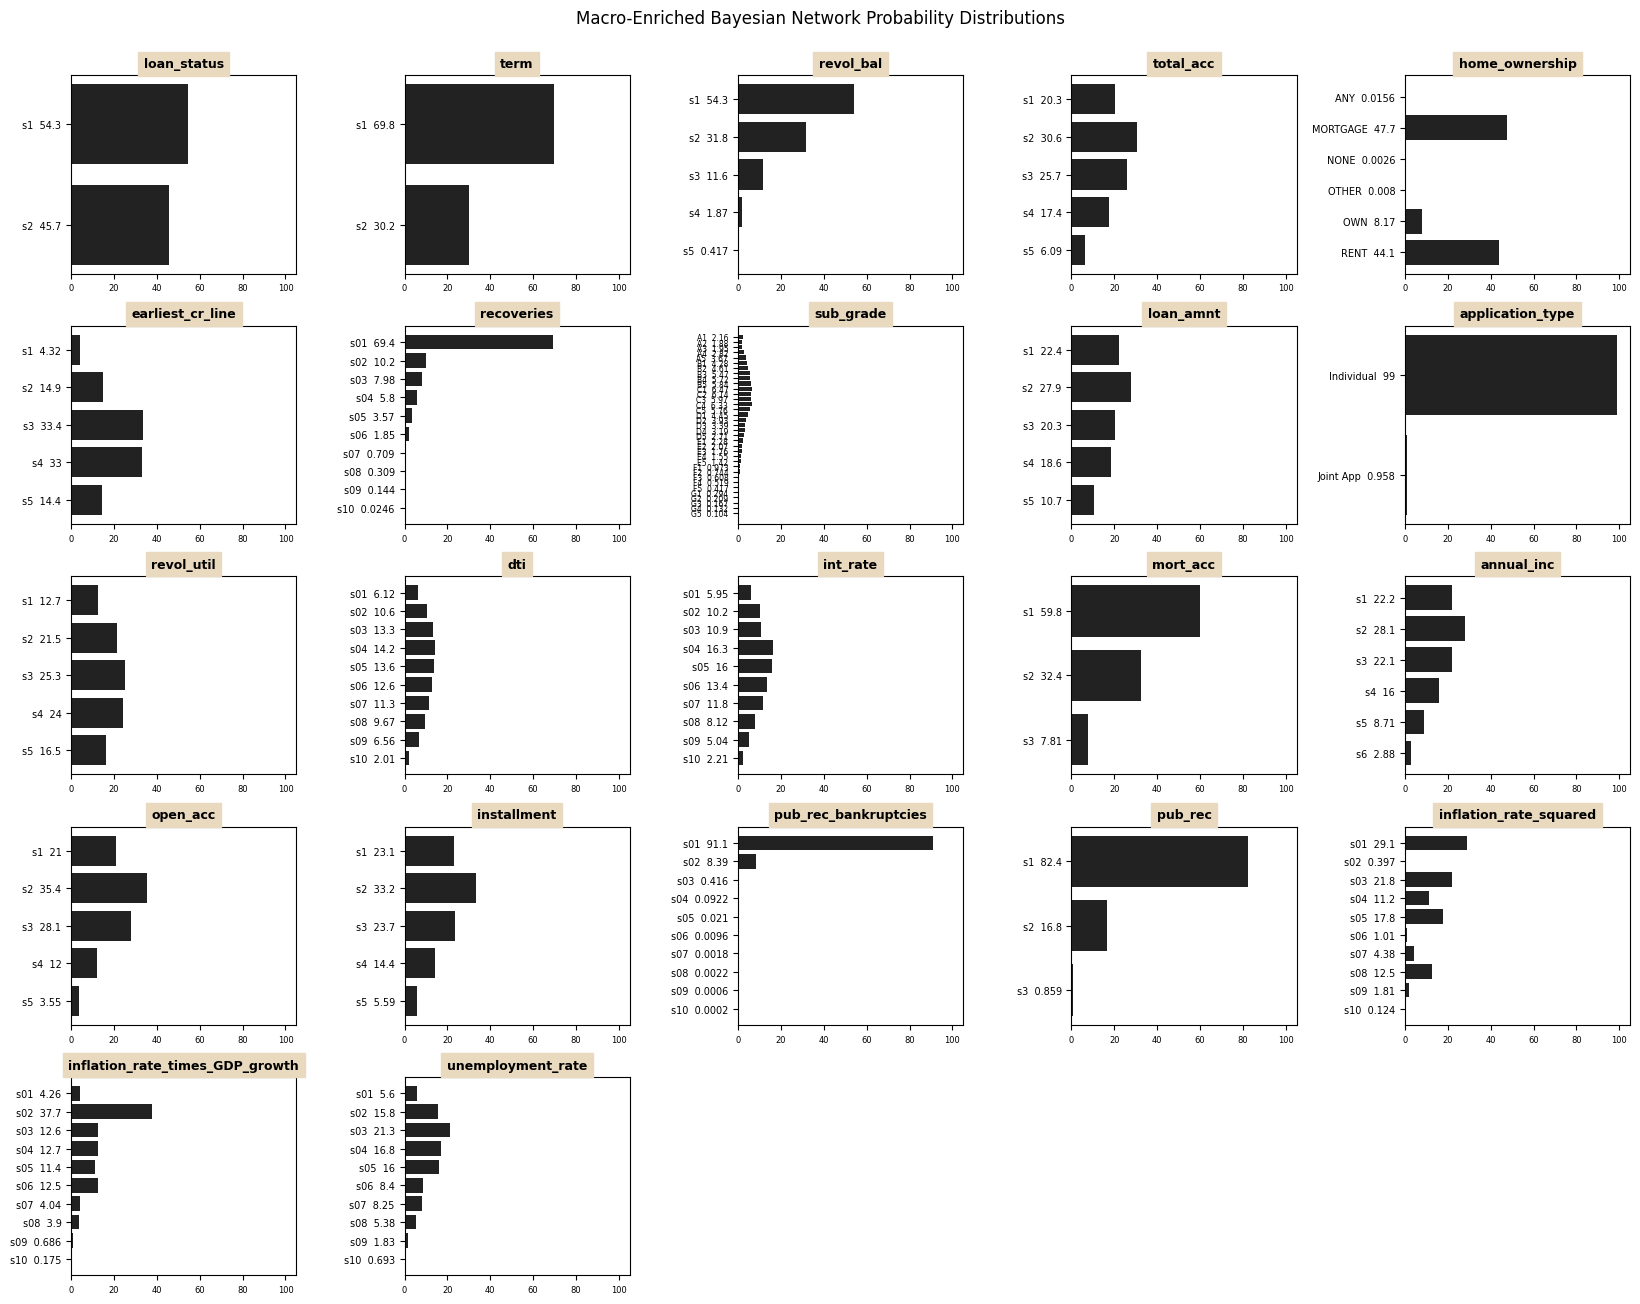

Prior P(loan_status): baseline s1/s2 = 54.0/46.0  (paper Fig. 10: 49.8/50.2) | enriched = 54.3/45.7 (paper Fig. 11: 43.4/56.6)

===== Table 5 (BN baseline vs macro-enriched): REPRODUCED =====
                   Accuracy  ROC-AUC
Baseline BN           0.860    0.724
Macro-Enriched BN     0.869    0.726
----- Table 5 (BN baseline vs macro-enriched): PAPER -----
                   Accuracy  ROC-AUC
Baseline BN           0.846    0.725
Macro-Enriched BN     0.866    0.757
----- Table 5 (BN baseline vs macro-enriched): DIFFERENCE (reproduced - paper) -----
                   Accuracy  ROC-AUC
Baseline BN           0.014   -0.001
Macro-Enriched BN     0.003   -0.031


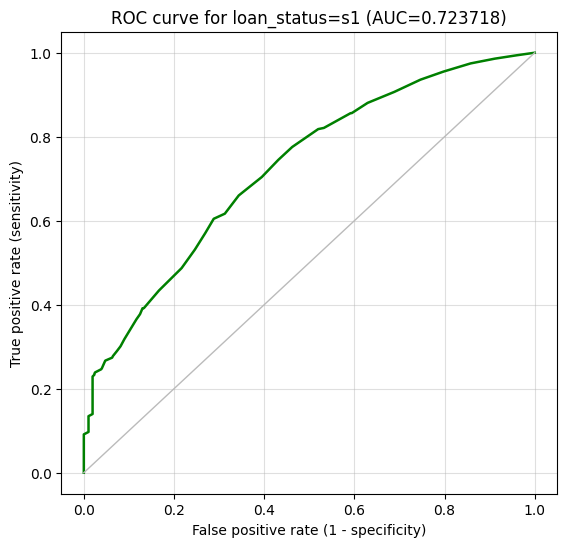

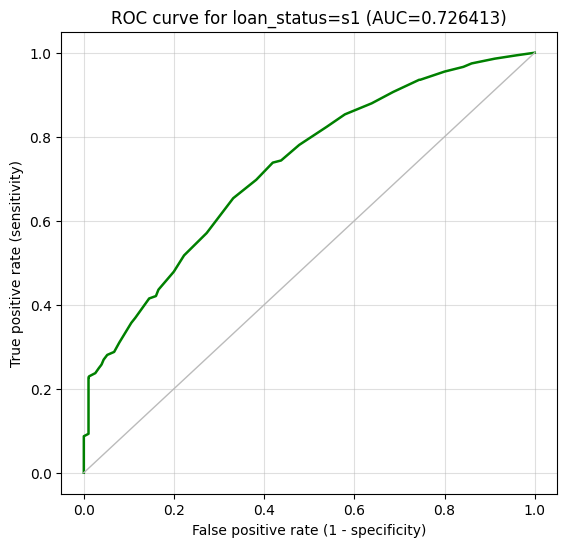

Confusion matrix Baseline BN (rows=actual [default, paid], cols=predicted):
 [[ 2017  6539]
 [ 1078 44714]]
Confusion matrix Macro-enriched BN (rows=actual [default, paid], cols=predicted):
 [[ 1939  6617]
 [  480 45312]]

===== Table 6 (ML vs Bayesian network): REPRODUCED =====
                      Accuracy  ROC-AUC  Precision  Recall  F1-Score  KS_Statistic  Brier Score    ECE
Gradient Boosting        0.882    0.752      0.877   1.000     0.934         0.353        0.107  0.087
LightGBM                 0.881    0.754      0.878   0.997     0.934         0.356        0.104  0.050
XGBoost                  0.877    0.758      0.879   0.990     0.931         0.362        0.103  0.047
Random Forest            0.870    0.739      0.879   0.981     0.927         0.319        0.126  0.149
Logistic Regression      0.819    0.726      0.890   0.896     0.893         0.321        0.136  0.142
Neural Network           0.498    0.675      0.904   0.452     0.603         0.240        0.432  0.444

In [28]:
def eval_bn(bn, Cte):
    y = Cte[:, bn.T]; p = bn.predict_paid(Cte); return evaluate(y, p), y, p

def build_bn(tag, train_df, test_df, nodes, learners=("tabu",)):
    t0 = time.time(); rng = np.random.default_rng(RANDOM_STATE)
    disc = BNDiscretizer(nodes).fit(train_df); Ctr = disc.transform(train_df); Cte = disc.transform(test_df)
    names, cards, T = nodes, disc.cards, nodes.index(TARGET)
    rows = rng.choice(len(Ctr), min(STRUCT_ROWS, len(Ctr)), replace=False)
    forbid = {(T, i) for i in range(len(nodes)) if i != T}                 # arc constraint: loan_status is an outcome node (sink)
    mis = {i: mutual_info(Ctr[rows], i, T, cards[i], 2) for i in range(len(nodes)) if i != T}
    init = [(i, T) for i, m in sorted(mis.items(), key=lambda kv: -kv[1])[:3] if m > 1e-3]   # MI-threshold initial arcs
    structures = {}
    print(f"[{tag}] learning structures on {len(rows):,} rows ...")
    if "tabu" in learners:
        structures["Tabu search"] = local_search(len(nodes), ScoreCache(Ctr[rows], cards, "bic"), forbid, BN_MAX_INDEGREE, init,
                                                 "tabu", patience=TABU_PATIENCE, max_iter=TABU_MAX_ITER, label="Tabu")
    if "others" in learners:
        structures["Bayesian search"] = local_search(len(nodes), ScoreCache(Ctr[rows], cards, "bdeu", 1.0), forbid, BN_MAX_INDEGREE, [],
                                                     "hill", restarts=3, seed=7, max_iter=TABU_MAX_ITER, label="Bayesian search")
        try:
            structures["PC"] = learn_pc(Ctr, names, cards, rng.choice(len(Ctr), min(PC_ROWS, len(Ctr)), replace=False)); print("    [PC] arcs =", sum(map(len, structures["PC"])))
        except Exception as e:
            print("    [PC] failed:", repr(e)[:150]); structures["PC"] = None
        structures["Naive Bayes"] = [[T] if i != T else [] for i in range(len(nodes))]
    results, bns = {}, {}
    for nm, par in structures.items():
        if par is None: results[nm] = {"AUC": np.nan, "KS": np.nan, "Brier score": np.nan, "Accuracy": np.nan, "arcs": np.nan}; continue
        bn = DiscreteBN(names, cards, par).fit_em(Ctr); m, y, p = eval_bn(bn, Cte); bns[nm] = (bn, y, p)
        results[nm] = {"AUC": m["ROC-AUC"], "KS": m["KS_Statistic"], "Brier score": m["Brier Score"], "Accuracy": m["Accuracy"],
                       "arcs": sum(map(len, par)), **{"_m": m}}
    print(f"[{tag}] done in {time.time()-t0:.0f}s")
    return dict(disc=disc, Ctr=Ctr, Cte=Cte, names=names, cards=cards, results=results, bns=bns, T=T)

def load_or_build_bn(tag, train_df, test_df, nodes, learners):
    """Load a fully fitted BN bundle when saved; otherwise learn, fit with EM, and checkpoint."""
    path = os.path.join(CACHE_DIR, f"bn_{tag}_complete.pkl")
    if os.path.exists(path):
        try:
            with open(path, "rb") as f:
                obj = pickle.load(f)
            print(f"\n[{tag}] REUSING saved BN bundle: {path}")
            return obj
        except Exception as exc:
            print(f"[{tag}] saved bundle could not be loaded ({exc!r}); rebuilding.")
    obj = build_bn(tag, train_df, test_df, nodes, learners=learners)
    tmp = path + ".tmp"
    with open(tmp, "wb") as f:
        pickle.dump(obj, f, protocol=pickle.HIGHEST_PROTOCOL)
    os.replace(tmp, path)
    print(f"[{tag}] saved fitted BN bundle: {path}")
    return obj

BN_BASE = load_or_build_bn("baseline", smote_base, test_base, BN_BASE_NODES, learners=("tabu", "others"))
BN_ENR  = load_or_build_bn("macro_enriched", smote_enr, test_enr, BN_ENRICH_NODES, learners=("tabu",))

# ---- Table A.8 : comparison of structure learning algorithms (baseline BN)
A8 = pd.DataFrame({k: {c: v[c] for c in ("AUC", "KS", "Brier score")} for k, v in BN_BASE["results"].items()}).T
A8 = A8.reindex(["Tabu search", "Bayesian search", "PC", "Naive Bayes"]); save_table(A8.round(3), "TableA8_structure_learners")
compare_with_paper(A8, PAPER_A8, "Table A.8 (structure learning algorithms)")
best_learner = A8["AUC"].idxmax(); print("Best AUC:", best_learner, "(paper: Tabu search retained)")

# ---- Table A.7 : discretisation
A7 = BN_ENR["disc"].table_a7(); save_table(A7, "TableA7_discretization", index=False)
print("\nTable A.7 - K-means discretisation (macro-enriched BN training data)\n", A7.to_string(index=False))

# ---- Fig. 8 / Fig. 9 : structures
bn_b, yb, pb = BN_BASE["bns"]["Tabu search"]; bn_e, ye, pe = BN_ENR["bns"]["Tabu search"]
print("\nEM convergence (log-likelihood per iteration), baseline:", [round(v) for v in bn_b.em_history[:4]], "...")
plot_structure(bn_b, "Baseline Bayesian Network Structure for Credit Risk Prediction (Tabu search)", "Fig8_baseline_BN_structure")
plot_structure(bn_e, "Macro-Enriched Bayesian Network Structure for Credit Risk Prediction (Tabu search)", "Fig9_macro_enriched_BN_structure")
save_table(pd.DataFrame(bn_b.edges(), columns=["from", "to"]), "BN_baseline_edges", index=False)
save_table(pd.DataFrame(bn_e.edges(), columns=["from", "to"]), "BN_enriched_edges", index=False)

# ---- Fig. 10 / 11 : learned probability distributions (prior marginals)
for bn, B, nm, fig_ in [(bn_b, BN_BASE, "Baseline", "Fig10_baseline_BN_distributions"), (bn_e, BN_ENR, "Macro-Enriched", "Fig11_macro_enriched_BN_distributions")]:
    c, w = bn.sample(PRIOR_SAMPLES, None, np.random.default_rng(3)); B["prior"] = weighted_marginals(bn, c, w)
    plot_marginals(bn, B["disc"], B["prior"], f"{nm} Bayesian Network Probability Distributions", fig_)
print("Prior P(loan_status): baseline s1/s2 = {:.1f}/{:.1f}  (paper Fig. 10: 49.8/50.2) | enriched = {:.1f}/{:.1f} (paper Fig. 11: 43.4/56.6)".format(
      *(100 * BN_BASE["prior"][bn_b.T]), *(100 * BN_ENR["prior"][bn_e.T])))

# ---- Table 5 + ROC curves (Fig. A.1, A.2)
m_b, m_e = BN_BASE["results"]["Tabu search"]["_m"], BN_ENR["results"]["Tabu search"]["_m"]
T5 = pd.DataFrame({"Accuracy": [m_b["Accuracy"], m_e["Accuracy"]], "ROC-AUC": [m_b["ROC-AUC"], m_e["ROC-AUC"]]}, index=["Baseline BN", "Macro-Enriched BN"])
save_table(T5.round(3), "Table5_BN_performance"); compare_with_paper(T5, PAPER_T5, "Table 5 (BN baseline vs macro-enriched)")
plot_roc(yb, pb, "Baseline BN", "FigA1_ROC_baseline_BN"); plot_roc(ye, pe, "Macro-enriched BN", "FigA2_ROC_macro_enriched_BN")
for nm, m in [("Baseline BN", m_b), ("Macro-enriched BN", m_e)]:
    y, p = (yb, pb) if nm.startswith("Base") else (ye, pe); cm = confusion_matrix(y, (p >= .5).astype(int))
    print(f"Confusion matrix {nm} (rows=actual [default, paid], cols=predicted):\n", cm)

# ---- Table 6 : ML (macro-enriched) vs BN
BN_ROW = pd.DataFrame([m_e], index=["Bayesian Network"])[METRICS]
if T4 is not None:
    T6 = pd.concat([T4, BN_ROW]); save_table(T6.round(3), "Table6_ML_vs_BN")
    compare_with_paper(T6, pd.concat([PAPER_T4, PAPER_BN_ROW]), "Table 6 (ML vs Bayesian network)")
    rk = T6["Brier Score"].rank().loc["Bayesian Network"]; print(f"BN calibration rank by Brier score: {int(rk)} of {len(T6)} (paper: top three)")
else:
    save_table(BN_ROW.round(3), "Table6_BN_row_only"); compare_with_paper(BN_ROW, PAPER_BN_ROW, "Table 6 (BN row)")

## 16. Sensitivity analysis — Figures 12–15

Parameter sensitivity for the baseline and macro-enriched BNs: color-coded network relevance and tornado diagrams.

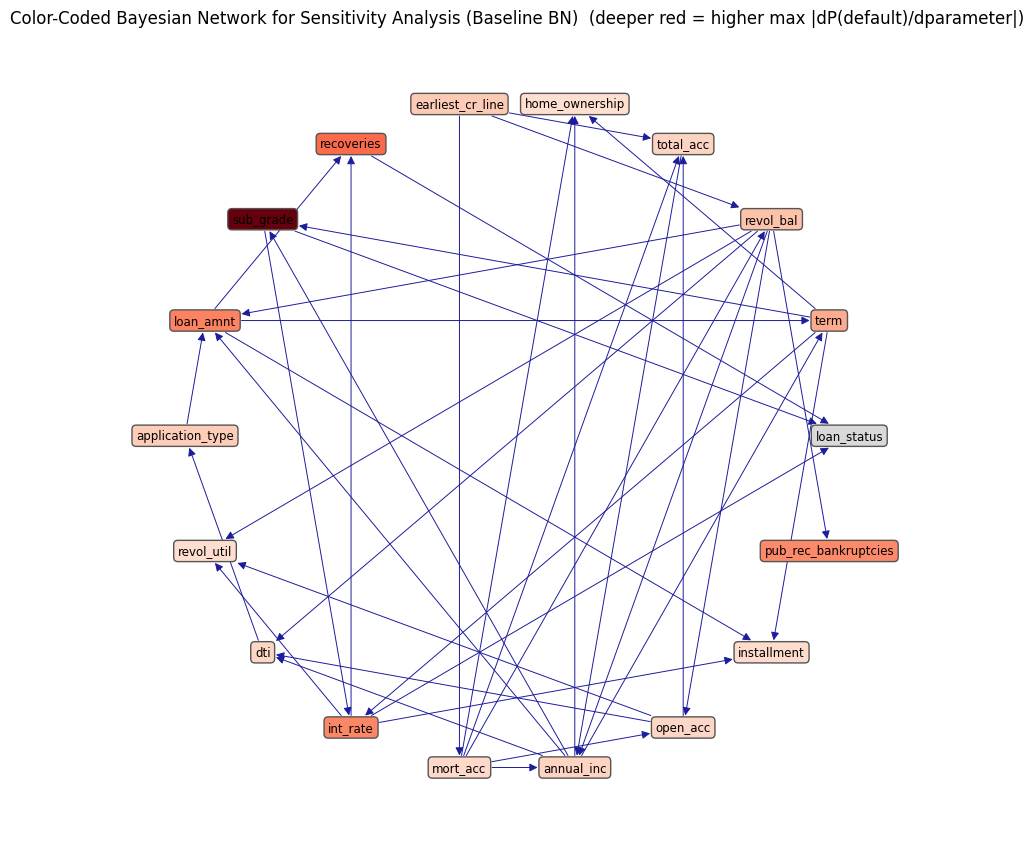

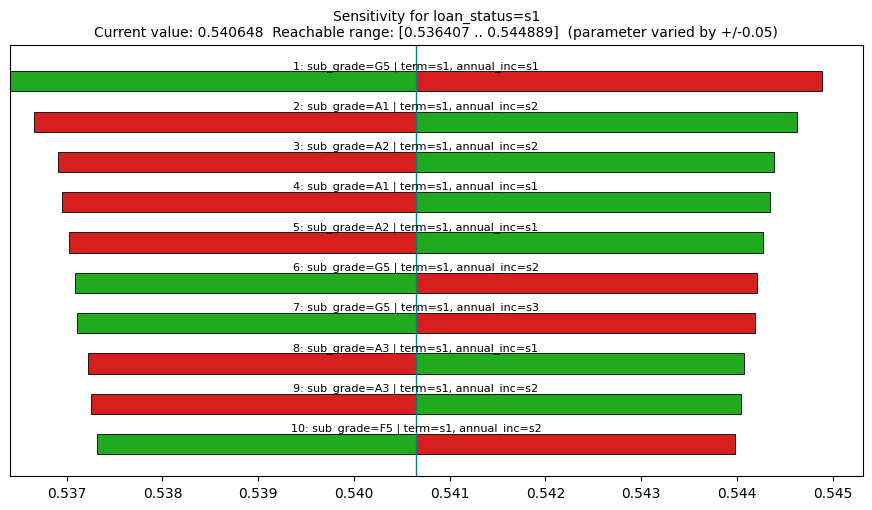


Baseline BN: most sensitive nodes -> {'sub_grade': 0.0848, 'recoveries': 0.0364, 'loan_amnt': 0.0294, 'loan_status': 0.0278, 'int_rate': 0.0278, 'pub_rec_bankruptcies': 0.0274}
Top-10 tornado parameters:
   1. sub_grade=G5 | term=s1, annual_inc=s1                                  dP/dtheta = +0.0848
   2. sub_grade=A1 | term=s1, annual_inc=s2                                  dP/dtheta = -0.0797
   3. sub_grade=A2 | term=s1, annual_inc=s2                                  dP/dtheta = -0.0748
   4. sub_grade=A1 | term=s1, annual_inc=s1                                  dP/dtheta = -0.0739
   5. sub_grade=A2 | term=s1, annual_inc=s1                                  dP/dtheta = -0.0726
   6. sub_grade=G5 | term=s1, annual_inc=s2                                  dP/dtheta = +0.0712
   7. sub_grade=G5 | term=s1, annual_inc=s3                                  dP/dtheta = +0.0709
   8. sub_grade=A3 | term=s1, annual_inc=s1                                  dP/dtheta = -0.0685
   9. sub_grade=A3 

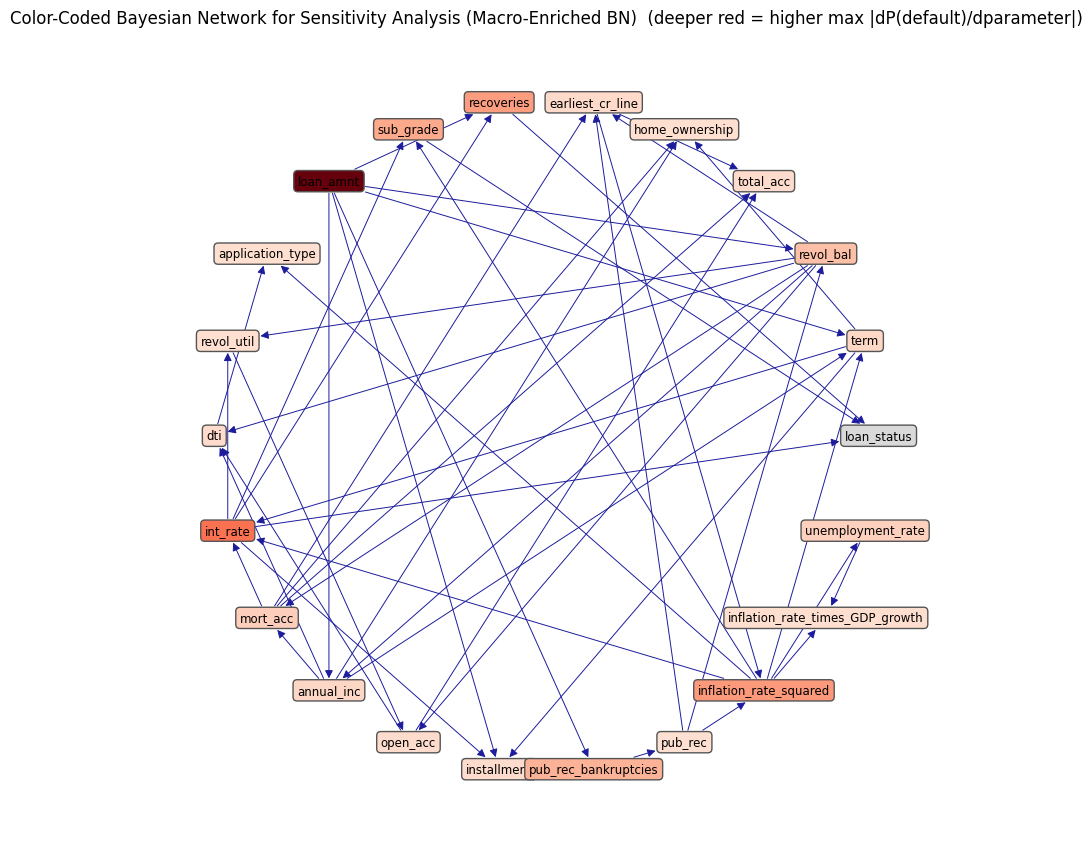

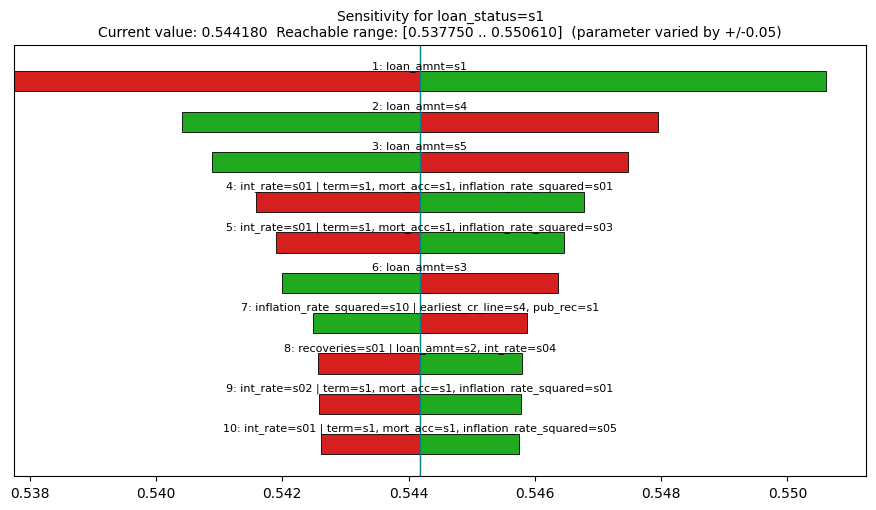


Macro-Enriched BN: most sensitive nodes -> {'loan_amnt': 0.1286, 'int_rate': 0.0519, 'inflation_rate_squared': 0.034, 'recoveries': 0.0324, 'loan_status': 0.0277, 'sub_grade': 0.0271}
Top-10 tornado parameters:
   1. loan_amnt=s1                                                           dP/dtheta = -0.1286
   2. loan_amnt=s4                                                           dP/dtheta = +0.0754
   3. loan_amnt=s5                                                           dP/dtheta = +0.0659
   4. int_rate=s01 | term=s1, mort_acc=s1, inflation_rate_squared=s01        dP/dtheta = -0.0519
   5. int_rate=s01 | term=s1, mort_acc=s1, inflation_rate_squared=s03        dP/dtheta = -0.0456
   6. loan_amnt=s3                                                           dP/dtheta = +0.0436
   7. inflation_rate_squared=s10 | earliest_cr_line=s4, pub_rec=s1           dP/dtheta = +0.0340
   8. recoveries=s01 | loan_amnt=s2, int_rate=s04                            dP/dtheta = -0.0324
   9. int_ra

In [43]:
# %%
SENS = {}
for bn, B, tag, f_col, f_tor, nm in [(bn_b, BN_BASE, "baseline", "Fig12_colorcoded_baseline_BN", "Fig14_tornado_baseline_BN", "Baseline BN"),
                                      (bn_e, BN_ENR, "enriched", "Fig13_colorcoded_enriched_BN", "Fig15_tornado_enriched_BN", "Macro-Enriched BN")]:
    P, recs = sensitivity(bn, PRIOR_SAMPLES)
    node_score = plot_colored_network(bn, recs, f"Color-Coded Bayesian Network for Sensitivity Analysis ({nm})", f_col)
    top = plot_tornado(bn, B["disc"], P, recs, f"Tornado ({nm})", f_tor)
    SENS[tag] = (node_score, top)
    print(f"\n{nm}: most sensitive nodes ->", node_score.head(6).round(4).to_dict())
    print("Top-10 tornado parameters:"); [print(f"  {k+1:2d}. {lab:70s} dP/dtheta = {d:+.4f}") for k, (lab, d) in enumerate(top)]
print("\nPaper: baseline = term, pub_rec_bankruptcies, sub_grade deep red; enriched = unemployment_rate, sub_grade, inflation_rate_squared deep red.")

## 17. Mutual-information analysis — Figures 16–17

Ranks features by mutual information with loan status for baseline and macro-enriched networks.

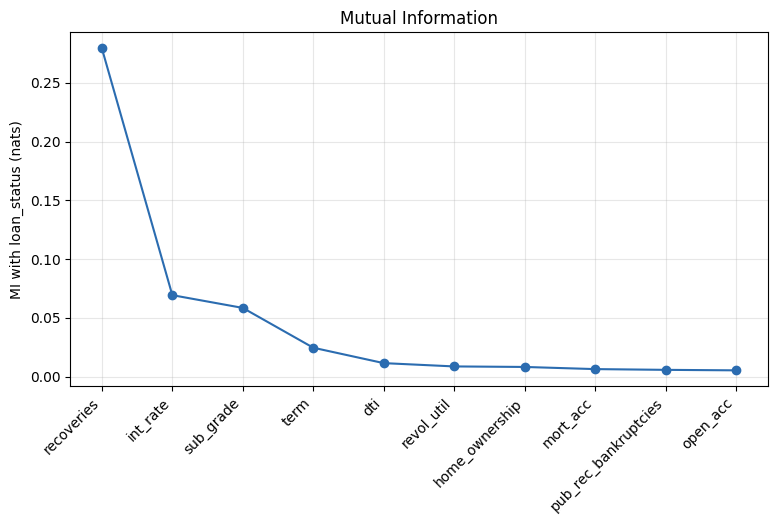

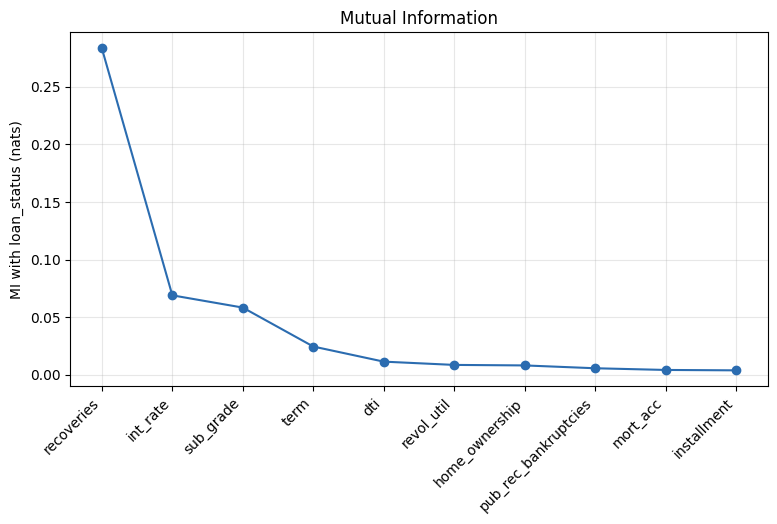

MI baseline (top-10):
 recoveries              0.2794
int_rate                0.0693
sub_grade               0.0585
term                    0.0246
dti                     0.0115
revol_util              0.0087
home_ownership          0.0082
mort_acc                0.0064
pub_rec_bankruptcies    0.0058
open_acc                0.0053 
MI enriched (top-10):
 recoveries              0.2832
int_rate                0.0690
sub_grade               0.0584
term                    0.0246
dti                     0.0115
revol_util              0.0087
home_ownership          0.0082
pub_rec_bankruptcies    0.0058
mort_acc                0.0043
installment             0.0040
Paper: dti, sub_grade, int_rate lead; term next (baseline). Enriched adds unemployment_rate and inflation_rate_times_GDP_growth.


In [44]:
# %%
mi_b = plot_mi(BN_BASE["Ctr"], bn_b, "Mutual information of the Baseline BN Model", "Fig16_MI_baseline_BN")
mi_e = plot_mi(BN_ENR["Ctr"], bn_e, "Mutual information of the Macro-Enriched BN Model", "Fig17_MI_macro_enriched_BN")
save_table(mi_b.to_frame("MI"), "Fig16_MI_values"); save_table(mi_e.to_frame("MI"), "Fig17_MI_values")
print("MI baseline (top-10):\n", mi_b.round(4).to_string(), "\nMI enriched (top-10):\n", mi_e.round(4).to_string())
print("Paper: dti, sub_grade, int_rate lead; term next (baseline). Enriched adds unemployment_rate and inflation_rate_times_GDP_growth.")

## 18. Forward inference — Figures 18–21

Scenario plots of default probability under selected combinations of loan term, DTI, interest rate, unemployment and inflation features.

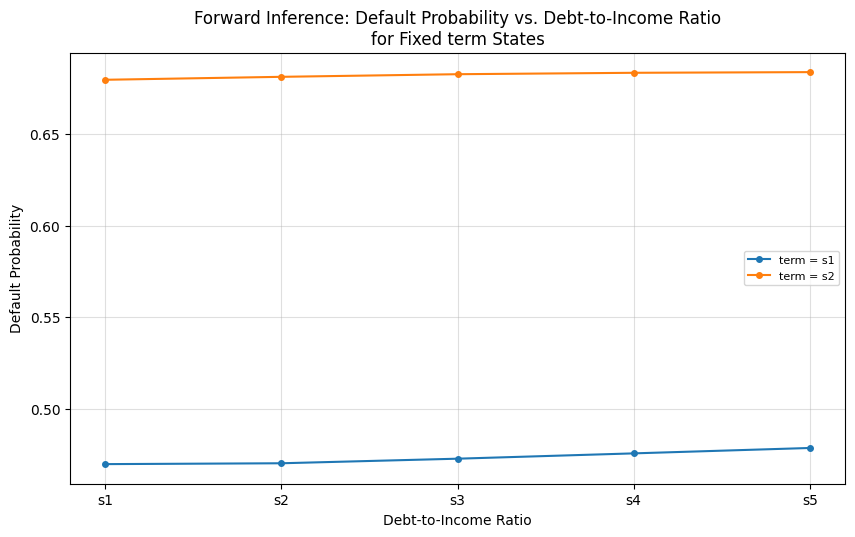

Fig. 18 values (paper: term=s1 44.5% -> 48.9%; term=s2 56.9% -> 60.4%)
      term = s1  term = s2
s01       47.0       68.0
s02       47.0       68.1
s03       47.3       68.3
s04       47.6       68.4
s05       47.9       68.4


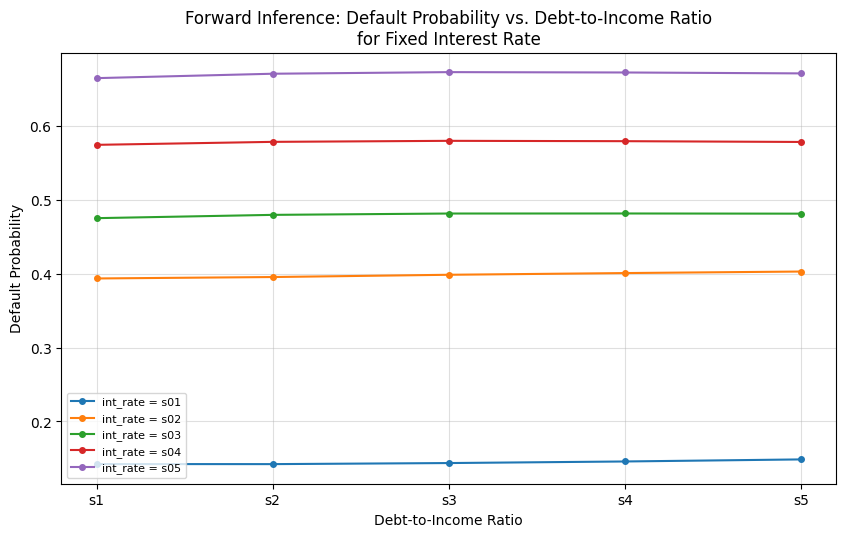

Fig. 19 values (paper: int_rate=s1 25.5% -> 30.6%; s5 about 71-72%)
      int_rate = s01  int_rate = s02  int_rate = s03  int_rate = s04  int_rate = s05
s01            14.2            39.4            47.5            57.5            66.5
s02            14.2            39.6            48.0            57.9            67.1
s03            14.4            39.9            48.2            58.0            67.3
s04            14.6            40.1            48.2            58.0            67.3
s05            14.9            40.3            48.2            57.9            67.2


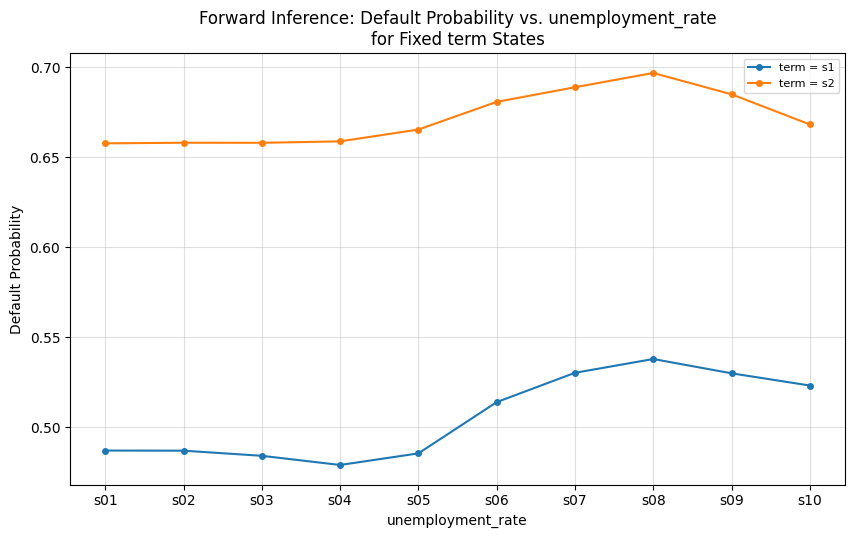

Fig. 20 values (paper: ~36% at s01 rising to >50% at s09)
      term = s1  term = s2
s01       48.7       65.8
s02       48.7       65.8
s03       48.4       65.8
s04       47.9       65.9
s05       48.6       66.5
s06       51.4       68.1
s07       53.0       68.9
s08       53.8       69.7
s09       53.0       68.5
s10       52.3       66.8


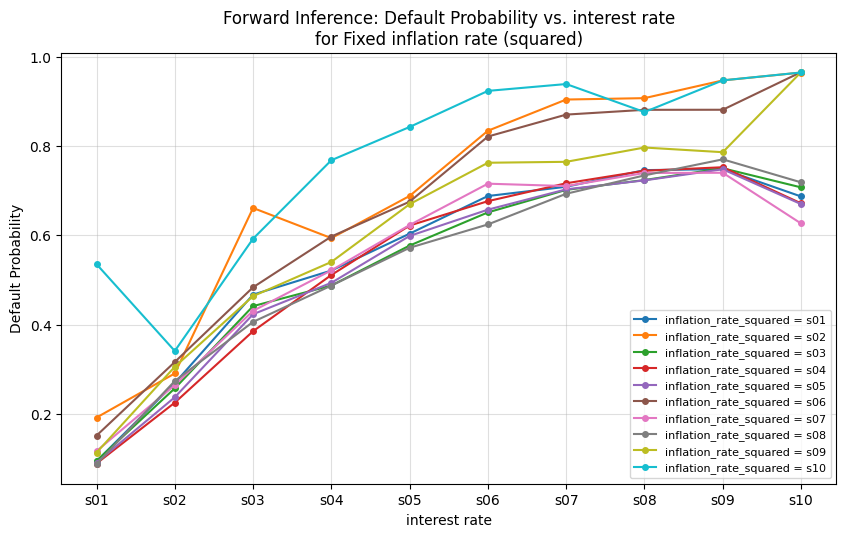

In [45]:
# %%
def idx_of(B, name): return B["names"].index(name)

def forward_plot(B, bn, line_var, line_states, x_var, x_states, title, xlabel, fname, legend_prefix, x_lab=None):
    iL, iX = idx_of(B, line_var), idx_of(B, x_var); fig, ax = plt.subplots(figsize=(10, 5.6)); table = {}
    for ls in line_states:
        ys = [p_default(bn, {iL: ls, iX: xs}, LW_SAMPLES, seed=11) for xs in x_states]
        table[f"{legend_prefix}{B['disc'].labels[line_var][ls]}"] = ys
        ax.plot(range(len(x_states)), ys, "-o", ms=4, label=f"{legend_prefix}{B['disc'].labels[line_var][ls]}")
    ax.set_xticks(range(len(x_states))); ax.set_xticklabels(x_lab or [B["disc"].labels[x_var][s] for s in x_states])
    ax.set_xlabel(xlabel); ax.set_ylabel("Default Probability"); ax.set_title(title); ax.grid(alpha=.4); ax.legend(fontsize=8)
    show_save(fig, fname)
    df = pd.DataFrame(table, index=[B["disc"].labels[x_var][s] for s in x_states]); save_table(df.round(4), fname + "_values"); return df

f18 = forward_plot(BN_BASE, bn_b, "term", [0, 1], "dti", range(5), "Forward Inference: Default Probability vs. Debt-to-Income Ratio\nfor Fixed term States",
                   "Debt-to-Income Ratio", "Fig18_forward_term_dti", "term = ", x_lab=[f"s{i}" for i in range(1, 6)])
print("Fig. 18 values (paper: term=s1 44.5% -> 48.9%; term=s2 56.9% -> 60.4%)\n", (100 * f18).round(1).to_string())
f19 = forward_plot(BN_BASE, bn_b, "int_rate", range(5), "dti", range(5), "Forward Inference: Default Probability vs. Debt-to-Income Ratio\nfor Fixed Interest Rate",
                   "Debt-to-Income Ratio", "Fig19_forward_intrate_dti", "int_rate = ", x_lab=[f"s{i}" for i in range(1, 6)])
print("Fig. 19 values (paper: int_rate=s1 25.5% -> 30.6%; s5 about 71-72%)\n", (100 * f19).round(1).to_string())
f20 = forward_plot(BN_ENR, bn_e, "term", [0, 1], "unemployment_rate", range(10), "Forward Inference: Default Probability vs. unemployment_rate\nfor Fixed term States",
                   "unemployment_rate", "Fig20_forward_term_unemployment", "term = ")
print("Fig. 20 values (paper: ~36% at s01 rising to >50% at s09)\n", (100 * f20).round(1).to_string())
f21 = forward_plot(BN_ENR, bn_e, "inflation_rate_squared", range(10), "int_rate", range(10), "Forward Inference: Default Probability vs. interest rate\nfor Fixed inflation rate (squared)",
                   "interest rate", "Fig21_forward_inflation_intrate", "inflation_rate_squared = ")

## 19. Backward inference — Figures 22–23

Sets evidence to default and records how each upstream node's distribution changes.

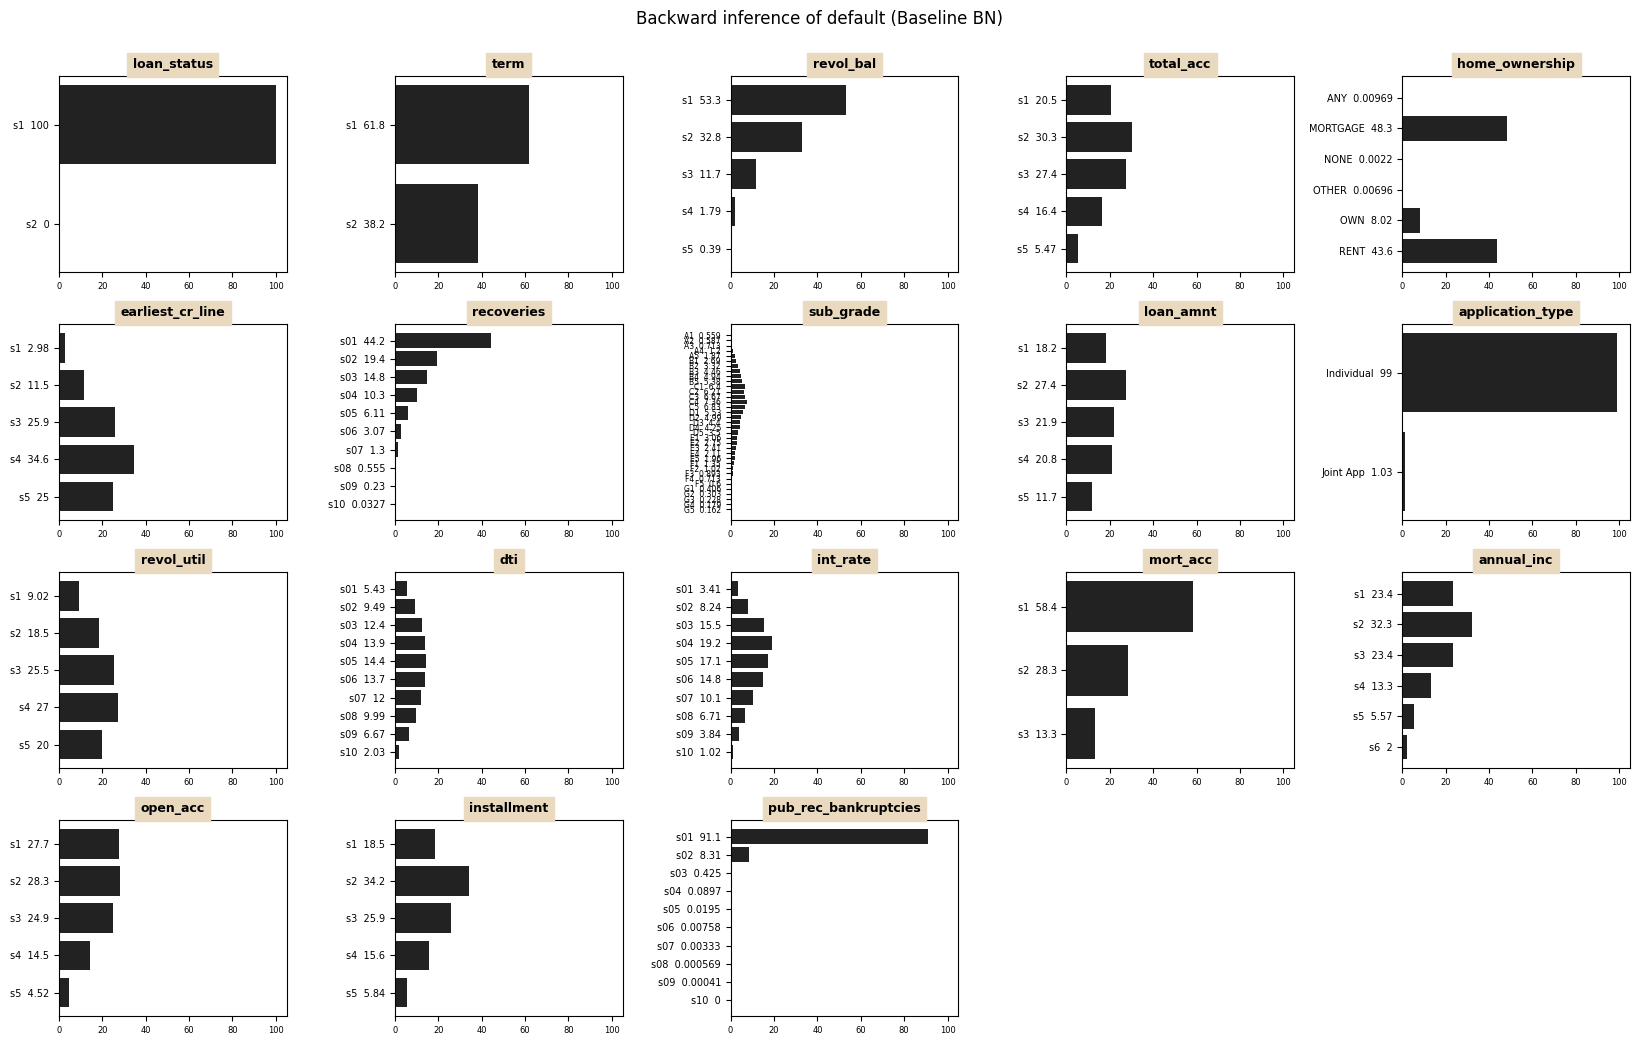


Baseline BN: largest posterior shifts given default:
        node  max_abs_shift_pp
loan_status             45.96
 recoveries             25.58
   int_rate              8.94
       term              7.97
installment              4.68
  loan_amnt              4.30


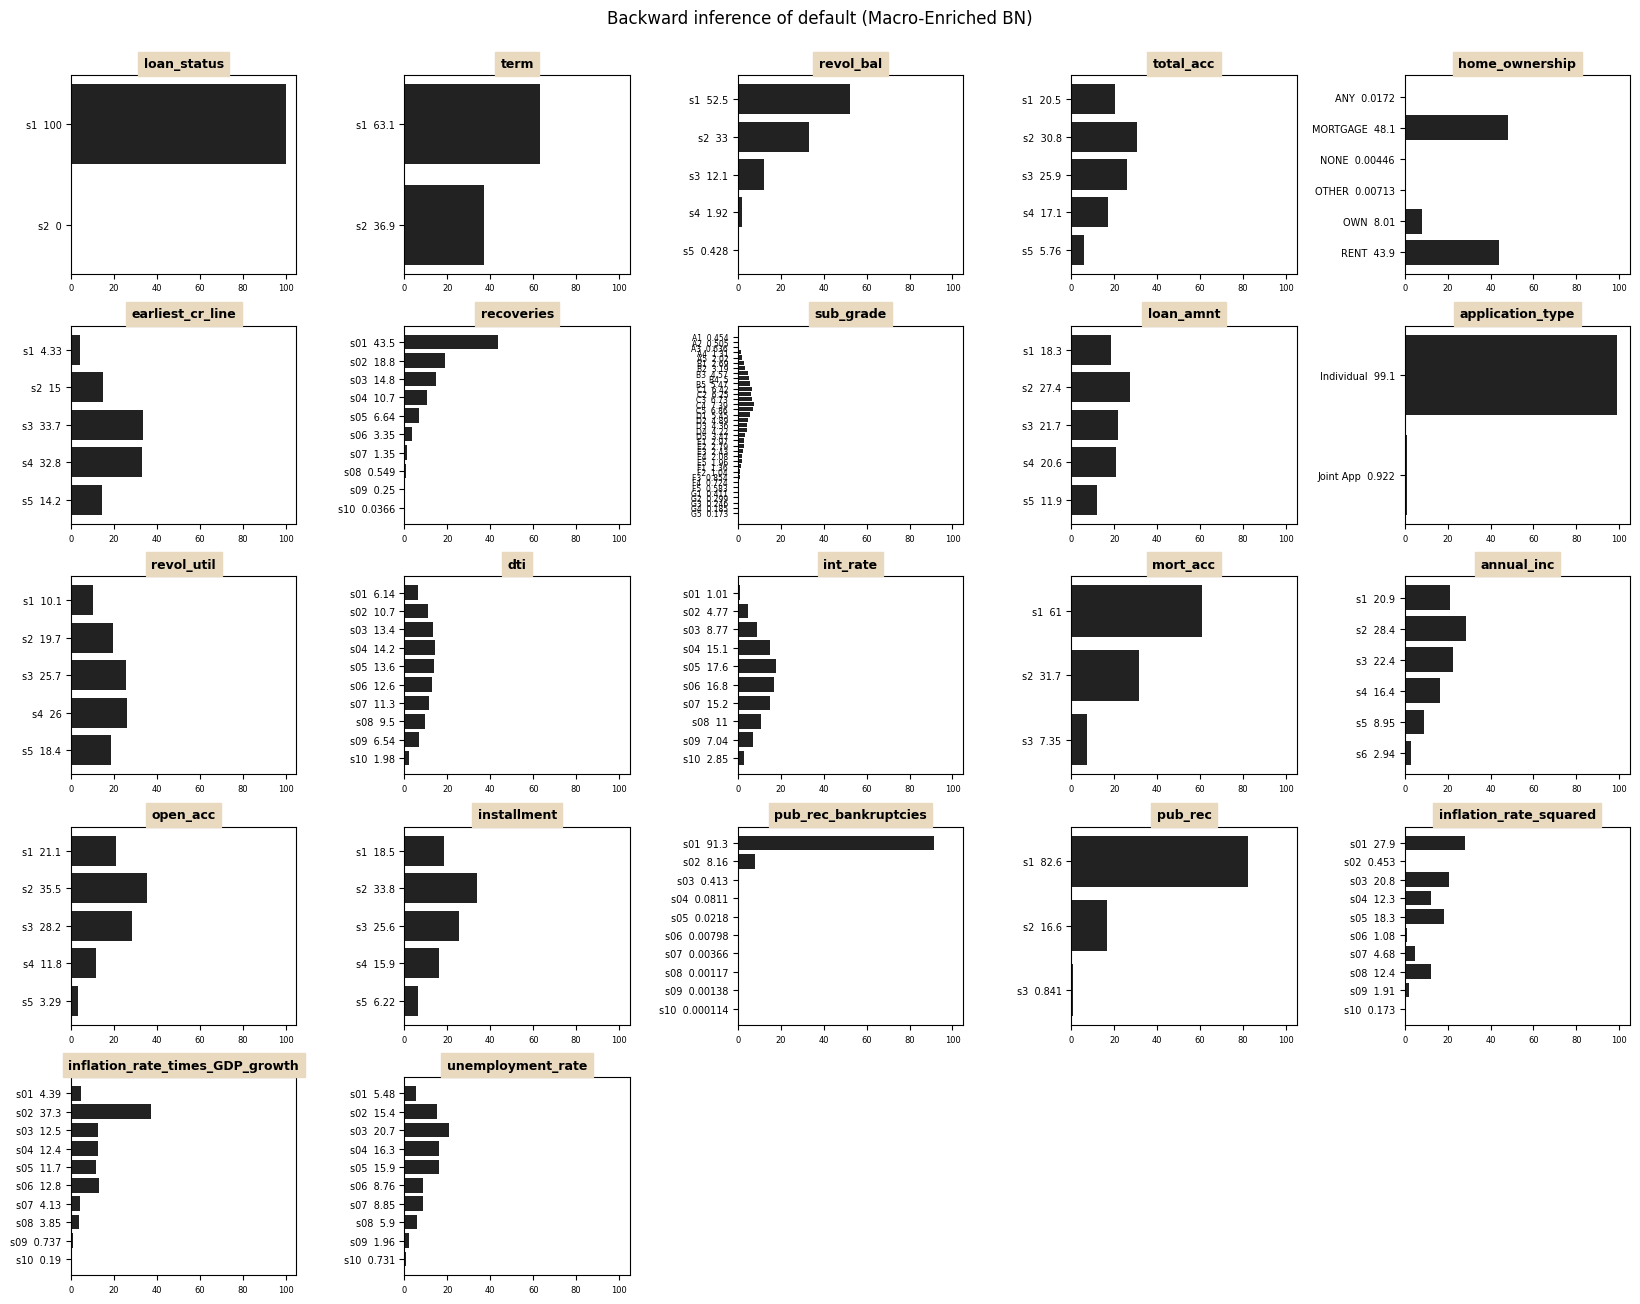


Macro-Enriched BN: largest posterior shifts given default:
        node  max_abs_shift_pp
loan_status             45.69
 recoveries             25.89
       term              6.67
   int_rate              5.47
installment              4.60
  loan_amnt              4.13


In [46]:
# %%
for bn, B, nm, fname in [(bn_b, BN_BASE, "Baseline BN", "Fig22_backward_inference_baseline_BN"), (bn_e, BN_ENR, "Macro-Enriched BN", "Fig23_backward_inference_macro_enriched_BN")]:
    c, w = bn.sample(PRIOR_SAMPLES, {bn.T: 0}, np.random.default_rng(5)); post = weighted_marginals(bn, c, w)
    plot_marginals(bn, B["disc"], post, f"Backward inference of default ({nm})", fname)
    shift = pd.DataFrame({"node": bn.names, "max_abs_shift_pp": [100 * np.abs(post[i] - B["prior"][i]).max() for i in range(bn.d)]}).sort_values("max_abs_shift_pp", ascending=False)
    save_table(shift, fname + "_posterior_shift", index=False); print(f"\n{nm}: largest posterior shifts given default:\n", shift.head(6).round(2).to_string(index=False))

## 20. Final output inventory and paper coverage

This cell lists every generated CSV/PNG and writes a manifest. Tables A.1–A.2 and Figures 1–3 are literature-review/framework assets in the paper, not model results derived from the LendingClub CSV; they are therefore reference-only. This workflow generates the analytical figures 4–23 and A.1–A.2 and the computational tables 1–6 and A.3–A.8.

In [35]:
# Ensure the Table A.3 feature list exists even if the configuration cell was edited.
if "SELECTED_COLS" in globals():
    save_table(pd.DataFrame({"Selected variable": SELECTED_COLS}), "TableA3_selected_variables", index=False)

fig_files = sorted(os.listdir(FIG_DIR))
tab_files = sorted(os.listdir(TAB_DIR))
manifest = []
for folder, files in [("figures", fig_files), ("tables", tab_files)]:
    for fn in files:
        manifest.append({"type": folder, "file": fn, "path": os.path.join(OUT_DIR, folder, fn)})
manifest_df = pd.DataFrame(manifest)
manifest_df.to_csv(os.path.join(OUT_DIR, "output_manifest.csv"), index=False)

print("\n" + "="*90)
print("STRUCTURED REPRODUCTION OUTPUTS")
print("Output root:", os.path.abspath(OUT_DIR))
print("Figures:", len(fig_files), "| Tables:", len(tab_files))
print("Manifest:", os.path.join(OUT_DIR, "output_manifest.csv"))
print("\nFigures generated:")
for f in fig_files: print(" -", f)
print("\nTables generated:")
for f in tab_files: print(" -", f)
print("\nPaper reference values: Table 5 baseline BN accuracy/AUC = 0.846/0.725; macro-enriched BN = 0.866/0.757.")
print("The paper also has one inconsistent prose value (87.60%); Table 5 and the later comparison use 86.6%.")


STRUCTURED REPRODUCTION OUTPUTS
Output root: /content/drive/MyDrive/LendingClub_Reproduction/outputs_paper_faithful_v7_structured
Figures: 22 | Tables: 23
Manifest: /content/drive/MyDrive/LendingClub_Reproduction/outputs_paper_faithful_v7_structured/output_manifest.csv

Figures generated:
 - Fig10_baseline_BN_distributions.png
 - Fig11_macro_enriched_BN_distributions.png
 - Fig12_colorcoded_baseline_BN.png
 - Fig13_colorcoded_enriched_BN.png
 - Fig14_tornado_baseline_BN.png
 - Fig15_tornado_enriched_BN.png
 - Fig16_MI_baseline_BN.png
 - Fig17_MI_macro_enriched_BN.png
 - Fig18_forward_term_dti.png
 - Fig19_forward_intrate_dti.png
 - Fig20_forward_term_unemployment.png
 - Fig21_forward_inflation_intrate.png
 - Fig22_backward_inference_baseline_BN.png
 - Fig23_backward_inference_macro_enriched_BN.png
 - Fig4_missing_value_histogram.png
 - Fig5_correlation_heatmap.png
 - Fig6_correlation_with_target.png
 - Fig7_catboost_importance_top22.png
 - Fig8_baseline_BN_structure.png
 - Fig9_macro_